## Imports:

In [800]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv
from knowledge_maze.tools.utils import load_json

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.create_dataset.create_answers.answer_orchestrator import AnswerGenerator
from knowledge_maze.create_dataset.create_answers.answer_qa_tagger import AnswerValidityTagger

question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Answer Generation:

In [867]:
generator = AnswerGenerator()
processed_dataset = generator.process_dataset(question_data)

Reasoning Strategy,Passed,Rejected
COUNT_TOTAL,144,0
AGGREGATION,21,0
EXTREME_NUMERICAL,35,0
TOP_K_RANKING,31,0
CATEGORICAL_FILTER_LOOKUP,47,1
FILTER_COUNT_NUMERICAL,29,3
COMPARATIVE_DIFFERENCE,33,0
UNIQUE_DIVERSITY,35,0
FREQUENCY_MODE,46,0
EXTREME_TEMPORAL,73,1


In [863]:
import pandas as pd
import numpy as np

# 1. Filter for numerical strategies only
num_strats = ['COUNT_TOTAL', 'AGGREGATION', 'TOP_K_RANKING', 'FILTER_COUNT_NUMERICAL', 'FILTER_COUNT_TEMPORAL', 'COMPARATIVE_DIFFERENCE']

results = []

for s in processed_dataset:
    strat = s.get('Selected strategy')
    if strat not in num_strats:
        continue
        
    try:
        # Extract numerical values
        true_val = float(s['Answer']['Memory'])
        claim_val = float(s['Answer']['Claim'])
        evid_val = float(s['Answer']['Evidence'])
        
        # Calculate absolute distances
        dist_claim = abs(true_val - claim_val)
        dist_evid = abs(true_val - evid_val)
        
        # Determine winner
        if dist_claim < dist_evid:
            winner = 'Claim'
        elif dist_evid < dist_claim:
            winner = 'Evidence'
        else:
            winner = 'Tie'
            
        results.append({'Strategy': strat, 'Winner': winner})
    except (ValueError, TypeError):
        continue

# 2. Generate Distribution Table
df_res = pd.DataFrame(results)
distribution = pd.crosstab(df_res['Strategy'], df_res['Winner'], normalize='index') * 100

print("### Proximity Distribution (%) per Strategy")
display(distribution.round(1))

### Proximity Distribution (%) per Strategy


Winner,Claim,Evidence,Tie
Strategy,,,
AGGREGATION,100.0,0.0,0.0
COMPARATIVE_DIFFERENCE,42.4,51.5,6.1
COUNT_TOTAL,43.1,36.8,20.1
FILTER_COUNT_NUMERICAL,69.0,6.9,24.1
FILTER_COUNT_TEMPORAL,60.5,27.9,11.6


In [864]:
confusability_data = []

for s in processed_dataset:
    strat = s.get('Selected strategy')
    if strat not in num_strats:
        continue
    
    try:
        t = float(s['Answer']['Memory'])
        c1 = float(s['Answer']['Claim'])
        c2 = float(s['Answer']['Evidence'])
        
        # Calculate all 3 internal distances
        dist_true_c1 = abs(t - c1)
        dist_true_c2 = abs(t - c2)
        dist_c1_c2 = abs(c1 - c2)
        
        # A sample is "Confusable" if the two lies are closer to each other 
        # than either one is to the truth.
        is_confusable = dist_c1_c2 < dist_true_c1 and dist_c1_c2 < dist_true_c2
        
        confusability_data.append({
            'Strategy': strat, 
            'Is_Confusable': is_confusable,
            'C1_C2_Gap': dist_c1_c2
        })
    except:
        continue

# Calculate Percentage per Strategy
df_confuse = pd.DataFrame(confusability_data)
summary = df_confuse.groupby('Strategy')['Is_Confusable'].mean() * 100

print("### Percentage of Samples where Counter 1 & 2 are 'Clustered' (Closer to each other than Truth)")
display(summary.to_frame(name='Confusability %').round(2))

### Percentage of Samples where Counter 1 & 2 are 'Clustered' (Closer to each other than Truth)


,Confusability %
Strategy,
AGGREGATION,4.76
COMPARATIVE_DIFFERENCE,84.85
COUNT_TOTAL,12.50
FILTER_COUNT_NUMERICAL,0.00
FILTER_COUNT_TEMPORAL,2.33


In [865]:
for s in processed_dataset:
    if s['Question'] == 'What is the difference in the number of appearances on The Simpsons between Marcia Wallace and Phil Hartman?':
        print(s['Answer'])

{'Memory': '127', 'Claim': '54', 'Evidence': '69'}


In [868]:
tagger = AnswerValidityTagger(processed_dataset, load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
tagger.display()

📦 Progress Loaded: 64 answer samples already tagged in 'answer_tagger_progress.json'.


Output()

In [870]:
# COUNT_TOTAL -------------------> Fixed
# AGGREGATION ------------------->
# EXTREME_NUMERICAL -------------> Fixed
# TOP_K_RANKING ----------------->
# CATEGORICAL_FILTER_LOOKUP ----->
# FILTER_COUNT_NUMERICAL -------->
# COMPARATIVE_DIFFERENCE --------> Fixed
# UNIQUE_DIVERSITY --------------> Fixed
# FREQUENCY_MODE ---------------->
# EXTREME_TEMPORAL -------------->
# FILTER_COUNT_TEMPORAL --------->

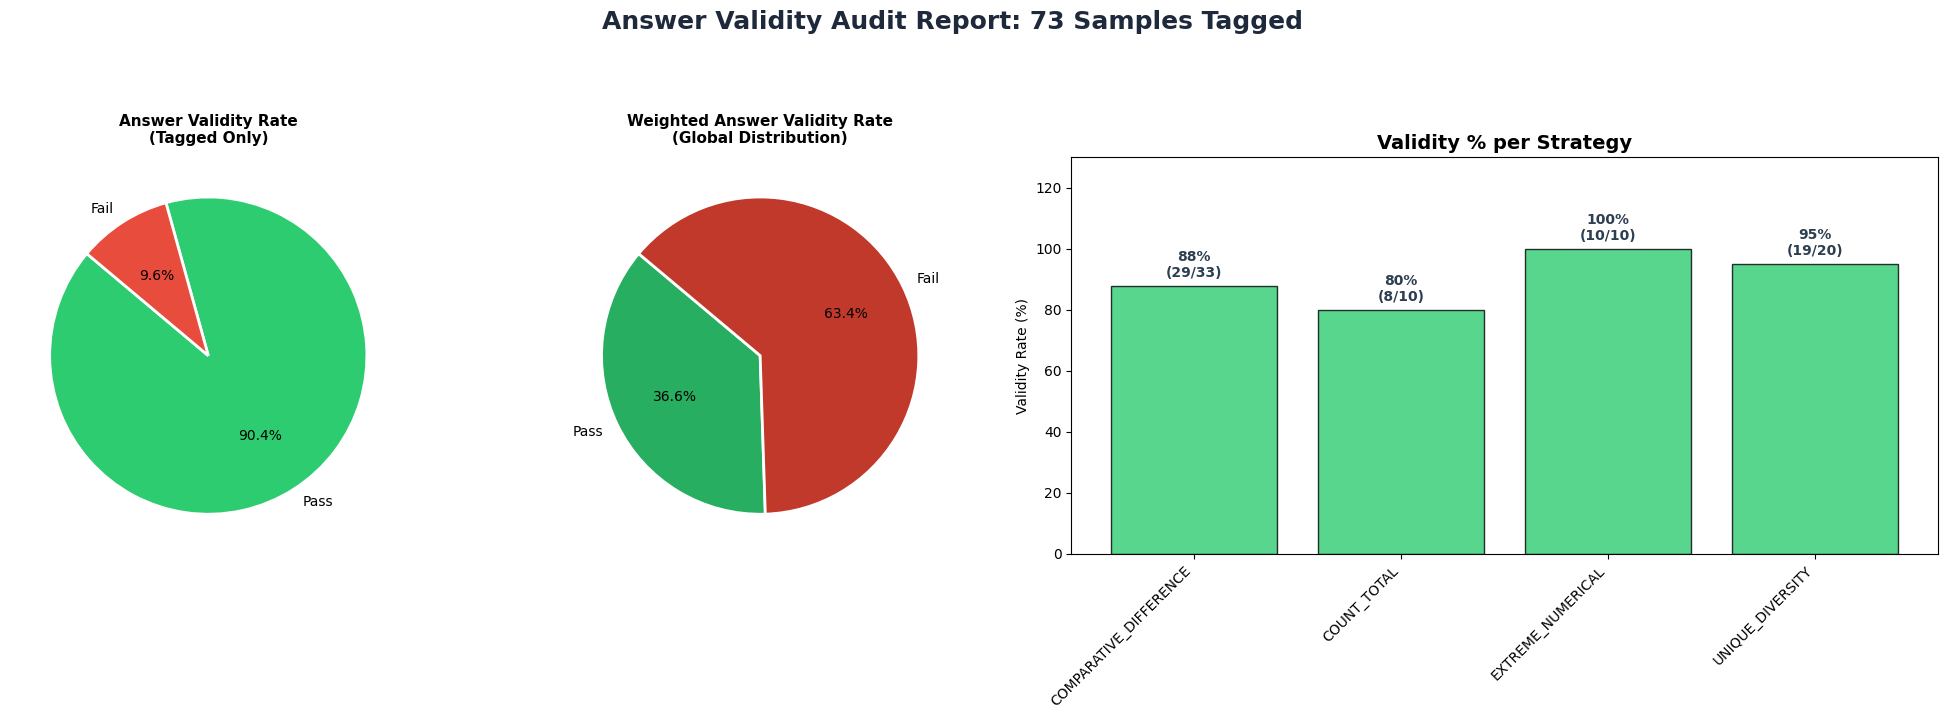

In [869]:
tagger.plot_results()

# Paragraph Generation:

## 1. Claim Paragraph Generation:

In [756]:
# Create the paragraphs
# Check a model can answer with the paragraph

## 2. Evidence Paragraph Generation:

In [757]:
# Create the paragraphs
# Check a model can answer with the paragraph

## 3. Get Distractor Paragraphs:

In [758]:
# Choose the most suitable paragraphs
# Make sure a model can't answer the question using only the distractors

# Test:

In [253]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/candidate_tables.jsonl"))
cleaned_data = processor.process()

Filtering & Cleaning:   0%|          | 0/64646 [00:00<?, ?it/s]

Legend / Key Filter,553
Header Parsing Failures,"3,883"
Cell Content Too Long,"1,937"
Malformed Row Structures,"1,604"
Alphabetical Lists Removed,639
Tables with no Headers,585
Long Tables Removed,"31,673"
Intra-Page Duplicates Removed,"8,872"


In [267]:
for sample in cleaned_data:
    sample['Group name'] = sample['table_name']['header_chain']
    sample['Table data'] = sample['rows']
    sample['Wiki url'] = None
    sample['Entity column'] = list(sample['rows'][0].keys())[0]

In [273]:
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector, QuestionGenerator, QuestionFilter

selector = StrategySelector(cleaned_data)
selector.get_strategies()

all_date_tables = []
for s in selector.updated_data:
    if 'EXTREME_TEMPORAL' in s['Top strategies']:
        all_date_tables.append(s['Strategy Views']['EXTREME_TEMPORAL'])
    elif 'FILTER_COUNT_TEMPORAL' in s['Top strategies']:
        all_date_tables.append(s['Strategy Views']['FILTER_COUNT_TEMPORAL'])
    else:
        pass

Sanitizing tables:   0%|          | 0/14900 [00:00<?, ?it/s]

Slicing strategy views:   0%|          | 0/14900 [00:00<?, ?it/s]

Strategy Name,Selection Count
COUNT_TOTAL,5769
EXTREME_TEMPORAL,3279
UNIQUE_DIVERSITY,2706
FILTER_COUNT_TEMPORAL,2351
FREQUENCY_MODE,1983
CATEGORICAL_FILTER_LOOKUP,1722
AGGREGATION,1355
COMPARATIVE_DIFFERENCE,1252
EXTREME_NUMERICAL,1150
TOP_K_RANKING,911


In [277]:
len(all_date_tables)

3279

In [276]:
all_date_tables = []
for s in selector.updated_data:
    if 'EXTREME_TEMPORAL' in s['Top strategies']:
        all_date_tables.append({'Relevant table data': s['Strategy Views']['EXTREME_TEMPORAL']})
    elif 'FILTER_COUNT_TEMPORAL' in s['Top strategies']:
        all_date_tables.append({'Relevant table data': s['Strategy Views']['FILTER_COUNT_TEMPORAL']})
    else:
        pass

In [286]:
from knowledge_maze.create_dataset.create_answers.utils.text_ops import TemporalTableParser

parser = TemporalTableParser()
valid_tables = []

for i, a in enumerate(tqdm(all_date_tables)):
    normalized_table = parser.parse_table_temporal_data(a)
    
    if normalized_table is not None:
        # Reconstruct 'a' with the cleaned, normalized table
        a['Parsed table data'] = normalized_table
        valid_tables.append(a)

# Print the final report summarizing how the data was handled
print(parser.get_summary_report())

  4%|██▉                                                                            | 124/3279 [00:07<03:09, 16.66it/s]

century!!!
century!!!


  6%|████▊                                                                          | 198/3279 [00:15<02:37, 19.57it/s]

century!!!
century!!!
century!!!


  9%|██████▋                                                                        | 280/3279 [00:21<03:35, 13.89it/s]

...

century!!!
century!!!
century!!!
century!!!
century!!!
century!!!


 98%|████████████████████████████████████████████████████████████████████████████▏ | 3205/3279 [03:46<00:03, 24.43it/s]

century!!!


100%|██████████████████████████████████████████████████████████████████████████████| 3279/3279 [03:50<00:00, 14.22it/s]

       TEMPORAL PARSER SUMMARY REPORT
Total Tables Analyzed:       3279
Valid Tables Normalized:     2818
Total Tables Discarded:      461
---------------------------------------------
Discard Reasons:
  - Logic/Parse Failures:    377
  - Insufficient Date Rows:  84
---------------------------------------------
Dominant Format Distribution (Valid Tables):
  - year           : 2167 ( 76.9%)
  - full_date      : 595 ( 21.1%)
  - month_year     :  56 (  2.0%)


In [283]:
for i, a in enumerate(random.sample(all_date_tables, 100)):
    if 'Parsed table data' not in list(a.keys()):
        display(pd.DataFrame(a['Relevant table data']))
        # display(pd.DataFrame(a['Parsed table data']))
        print("="*180)

,Name,Years active
0,Simon Dope (Erikh Ebejer),1997–2002
1,Tripp Eisen (Tod Rex Salvador),1997–2000
2,Preston Nash,1997–2000
3,"Sloane ""Mosey"" Jentry",1997–1999 2000–2004
4,Adrian Ost,2000–2001 2004 (touring)
5,"Racci ""Sketchy"" Shay Hart",2001–2005 2015–2017
6,"Brian ""Brix"" Milner",2004–2007
7,"Andrew ""Angel"" Bartolotta",2006–2013
8,"Derrick ""Tripp"" Tribbett",2007–2013
9,Nikk Dibs,2013–2015 2017–2018


,Name,Chapter and year
0,Charles E. Bennison,Lawrence 1965
1,Earl Cranston,Ohio 1861
2,Christopher Epting,Florida 1969
3,Gregory Parkes,Florida State University 1986


,Name,Population (2025)
0,"Federal Medical Center, Butner",830
1,"Federal Medical Center, Carswell",982
2,"Federal Medical Center, Devens",1063
3,"Federal Medical Center, Fort Worth",1513
4,"Federal Medical Center, Lexington",1058
5,"Federal Medical Center, Rochester",811
6,"Medical Center for Federal Prisoners, Springfield",1068


,Name,Years active
0,Al Atkins,1969–1973
1,K. K. Downing,1970–2011 2022 (guest)
2,John Ellis,1970–1971
3,"Alan ""Skip"" Moore",1971–1972 1975–1977
4,"Chris ""Congo"" Campbell",1972–1973
5,John Hinch,1973–1975 (died 2021)
6,Les Binks,1977–1979 2022 (guest) (died 2025)
7,Dave Holland,1979–1989 (died 2018)
8,"Tim ""Ripper"" Owens",1996–2003


,Name,Years active
0,S,2003; 2014
1,Kangta & Vanness,2006
2,SM the Ballad,2010; 2014
3,Younique Unit,2012
4,SM the Performance,2012–2013
5,Toheart,2014
6,SuperM,2019–2021
7,Got the Beat,2022–2023


...

,Name,Date
0,Siege of Ravenna (490–493),5 March 493
1,Siege of Naples (536),November 536
2,Ravenna massacre,537
3,Milan massacre,March 539
4,Ticinum massacre,539
5,Totila's sack of Rome,550
6,Massacre of aristocratic children,Late 552


,Name,Years active
0,Rob Halford,1993 1995
1,Rick Marty,1994
2,Keri Kelli,2005 2008
3,Ryan Cook,2007 2012
4,Alex Grossi,2008
5,Johny Dey,2015
6,Ryan Cook,2019
7,Casey Sproatt,2022 2023
8,Lzzy Hale,2024


,Name Reign,"Birth Date, location, parents"
0,George I ( Γεώργιος Αʹ ) 30 March 1863 – 18 Ma...,"24 December 1845 Copenhagen , Denmark Son of C..."
1,Constantine I ( Κωνσταντῖνος Αʹ ) 18 March 191...,"2 August 1868 Athens , Kingdom of Greece Son o..."
2,Alexander ( Ἀλέξανδρος ) 11 June 1917 – 25 Oct...,"1 August 1893 Athens , Kingdom of Greece Son o..."
3,Constantine I ( Κωνσταντῖνος Αʹ ) 19 December ...,"2 August 1868 Athens , Kingdom of Greece Son o..."
4,George II ( Γεώργιος Βʹ ) 27 September 1922 – ...,"19 July 1890 Athens , Kingdom of Greece Son of..."


,Battle or siege,Date
0,Battle for Knjaževac,"July 4 to 7, 1913"
1,Battle of Dobro Pole,"September 15 to 18, 1918"
2,Battle of Kalimanci,"July 18 to 19, 1913"
3,Battle of Kaymakchalan,"September 12 to 30, 1916"
4,Battle of Turtucaia,"September 2 to 6, 1916"
5,First Battle of Çatalca,"November 17 to 18, 1912"
6,Siege of Adrianople (1912–1913),"November 3, 1912 to March 26, 1913"
7,Battle of Bazargic,"September 5 to 7, 1916"


,Church,Dates
0,Lenora Methodist Episcopal Church,built NRHP-listed
1,Coleraine Methodist Episcopal Church,built NRHP-listed
2,St. Mark's African Methodist Episcopal Church,1913 built 1991 NRHP-listed
3,Portland Prairie Methodist Episcopal Church,built NRHP-listed
4,Hastings Methodist Episcopal Church,1862 built 1978 NRHP-listed
5,Fowler Methodist Episcopal Church,1906 built 1976 NRHP-listed
6,Wesley United Methodist Church,1891 built 1984 NRHP-listed
7,Norwood Methodist Episcopal Church,built NRHP-listed
8,Ottawa Methodist Episcopal Church,built NRHP-listed
9,Spring Valley Methodist Episcopal Church,built NRHP-listed


In [303]:
import pandas as pd
import dateparser
from datetime import datetime

def get_unified_full_date_table(sample):
    """
    Returns a unified table IF AND ONLY IF every value in the 
    temporal column is a complete 'Full Date' (Day, Month, Year).
    """
    # 1. Setup DataFrame
    rows = sample.get('Relevant table data', [])
    if not rows:
        return None
    
    df = pd.DataFrame(rows)
    # Assume the second column is the temporal one, else the first
    target_col = df.columns[1] if len(df.columns) > 1 else df.columns[0]
    ent_col = df.columns[0]
    
    unified_rows = []
    
    # 2. Strict Parse Loop
    for _, row in df.iterrows():
        raw_val = str(row[target_col])
        
        # We use a strict setting: if dateparser has to 'guess' a missing day, 
        # it usually uses the current day. We want to detect if the original 
        # string actually HAD those components.
        dt = dateparser.parse(raw_val, settings={
            'STRICT_PARSING': True, # Only matches if it looks like a date
            'REQUIRE_PARTS': ['day', 'month', 'year'] # The "Gold Standard" check
        })
        
        # If any row fails the 'Full Date' requirement, the whole table is rejected
        if dt is None:
            print(f"Rejected: '{raw_val}' is not a complete Full Date.")
            return None
        
        unified_rows.append({
            ent_col: row[ent_col],
            target_col: dt.strftime('%B %d, %Y'), # Standardize to: March 28, 2026
            "_sort_dt": dt
        })

    # 3. Final Sort and Return
    unified_rows.sort(key=lambda x: x["_sort_dt"])
    for r in unified_rows: 
        del r["_sort_dt"]
        
    return unified_rows

In [305]:
question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

valid_tables = []

for i, a in enumerate(question_data):
    if a.get('Selected strategy') in ["EXTREME_TEMPORAL", "FILTER_COUNT_TEMPORAL"]:
        # Parse and Normalize the table
        normalized_table = get_unified_full_date_table(a)
        
        if normalized_table is not None:
            # Reconstruct 'a' with the cleaned, normalized table
            a['Parsed table data'] = normalized_table
            valid_tables.append(a)

# Print the final report summarizing how the data was handled
for i, a in enumerate(question_data):
    if a.get('Selected strategy') in ["EXTREME_TEMPORAL", "FILTER_COUNT_TEMPORAL"]:
        if 'Parsed table data' in list(a.keys()):
            display(pd.DataFrame(a['Relevant table data']))
            display(pd.DataFrame(a['Parsed table data']))
            print("="*180)

Rejected: '2008' is not a complete Full Date.
Rejected: '2026' is not a complete Full Date.
Rejected: '9th–13th centuries' is not a complete Full Date.
Rejected: '1994–1996' is not a complete Full Date.
Rejected: '1969' is not a complete Full Date.
Rejected: '1843' is not a complete Full Date.
Rejected: 'May 2, 2008 ( 2008-05-02 )' is not a complete Full Date.
Rejected: '2012' is not a complete Full Date.
Rejected: '2002' is not a complete Full Date.
Rejected: '1901–1927' is not a complete Full Date.
Rejected: 'Apr 10, 1972 (W)' is not a complete Full Date.
Rejected: '1949' is not a complete Full Date.
Rejected: '2011' is not a complete Full Date.
Rejected: '1954' is not a complete Full Date.
Rejected: '1979–present' is not a complete Full Date.
Rejected: '1993–present' is not a complete Full Date.
Rejected: '2002' is not a complete Full Date.
Rejected: '2014' is not a complete Full Date.
Rejected: '1935–1944' is not a complete Full Date.
Rejected: 'November 7, 1861 ( 1861-11-07 )' is 

,Library,Date granted
0,Clarksdale,"Nov 21, 1911"
1,Greenwood,"Sep 29, 1911"
2,Gulfport,"May 15, 1916"
3,Houston,"Feb 25, 1908"
4,Jackson,"Jan 31, 1911"
5,Meridian Carnegie Library (white),"Dec 2, 1904"
6,Meridian Carnegie Library (black),"Dec 2, 1904"
7,Mound Bayou,"Feb 13, 1909"
8,Okolona,"Mar 11, 1914"
9,Vicksburg,"Jul 23, 1914"


,Library,Date granted
0,Meridian Carnegie Library (white),"December 02, 1904"
1,Meridian Carnegie Library (black),"December 02, 1904"
2,Houston,"February 25, 1908"
3,Mound Bayou,"February 13, 1909"
4,Jackson,"January 31, 1911"
5,Greenwood,"September 29, 1911"
6,Clarksdale,"November 21, 1911"
7,West Point,"January 31, 1913"
8,Okolona,"March 11, 1914"
9,Vicksburg,"July 23, 1914"


,Name,Release date
0,Spider-Man: No Way Home,"December 17, 2021"
1,Ghostbusters: Afterlife,"November 19, 2021"
2,No Time to Die,"October 8, 2021"
3,Venom: Let There Be Carnage,"October 1, 2021"
4,GUIMOON: The Lightless Door,"August 25, 2021"
5,Blackpink: The Movie,"August 4, 2021"
6,Escape from Mogadishu,"July 28, 2021"
7,Black Widow,"July 9, 2021"


,Name,Release date
0,Black Widow,"July 09, 2021"
1,Escape from Mogadishu,"July 28, 2021"
2,Blackpink: The Movie,"August 04, 2021"
3,GUIMOON: The Lightless Door,"August 25, 2021"
4,Venom: Let There Be Carnage,"October 01, 2021"
5,No Time to Die,"October 08, 2021"
6,Ghostbusters: Afterlife,"November 19, 2021"
7,Spider-Man: No Way Home,"December 17, 2021"


...

,Title,Premiere
0,Leona's Sister Gerri,"June 01, 1995"
1,Complaints of a Dutiful Daughter,"June 06, 1995"
2,No Place Like Home,"June 13, 1995"
3,Satya: A Prayer for the Enemy,"June 14, 1995"
4,Out of Sight,"June 20, 1995"
5,The Uprising of '34,"June 25, 1995"
6,Lighting the 7th Fire,"July 04, 1995"
7,Twitch and Shout,"July 11, 1995"
8,Home Economics: A Documentary of Suburbia,"July 18, 1995"
9,Dealers Among Dealers,"July 25, 1995"


,Movie,Original airdate
0,My Gal Sunday,"January 25, 2014"
1,The Redemption of Henry Myers,"March 23, 2014"
2,The Color of Rain,"May 31, 2014"
3,The Memory Book,"July 26, 2014"
4,Along Came a Nanny,"October 12, 2014"
5,Wedding Planner Mystery,"October 19, 2014"
6,Garage Sale Mystery : All That Glitters,"October 26, 2014"
7,"Signed, Sealed, Delivered for Christmas","November 23, 2014"
8,The Christmas Secret,"December 7, 2014"


,Movie,Original airdate
0,My Gal Sunday,"January 25, 2014"
1,The Redemption of Henry Myers,"March 23, 2014"
2,The Color of Rain,"May 31, 2014"
3,The Memory Book,"July 26, 2014"
4,Along Came a Nanny,"October 12, 2014"
5,Wedding Planner Mystery,"October 19, 2014"
6,Garage Sale Mystery : All That Glitters,"October 26, 2014"
7,"Signed, Sealed, Delivered for Christmas","November 23, 2014"
8,The Christmas Secret,"December 07, 2014"


,Name,Date of rank
0,Douglas MacArthur Class of 1903,18 December 1944
1,Dwight D. Eisenhower Class of 1915,20 December 1944
2,Henry H. Arnold Class of 1907,21 December 1944
3,Omar Bradley Class of 1915,22 September 1950


,Name,Date of rank
0,Douglas MacArthur Class of 1903,"December 18, 1944"
1,Dwight D. Eisenhower Class of 1915,"December 20, 1944"
2,Henry H. Arnold Class of 1907,"December 21, 1944"
3,Omar Bradley Class of 1915,"September 22, 1950"


In [299]:
from knowledge_maze.create_dataset.create_answers.utils.text_ops import TemporalTableParser

question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

parser = TemporalTableParser()
valid_tables = []

for i, a in enumerate(question_data):
    if a.get('Selected strategy') in ["EXTREME_TEMPORAL", "FILTER_COUNT_TEMPORAL"]:
        # Parse and Normalize the table
        normalized_table = parser.parse_table_temporal_data(a)
        
        if normalized_table is not None:
            # Reconstruct 'a' with the cleaned, normalized table
            a['Parsed table data'] = normalized_table
            valid_tables.append(a)

# Print the final report summarizing how the data was handled
print(parser.get_summary_report())

       TEMPORAL PARSER SUMMARY REPORT
Total Tables Analyzed:       161
Valid Tables Normalized:     142
Total Tables Discarded:      19
---------------------------------------------
Discard Reasons:
  - Logic/Parse Failures:    14
  - Insufficient Date Rows:  5
---------------------------------------------
Dominant Format Distribution (Valid Tables):
  - year           : 114 ( 80.3%)
  - full_date      :  24 ( 16.9%)
  - month_year     :   4 (  2.8%)


In [301]:
for i, a in enumerate(question_data):
    if a.get('Selected strategy') in ["EXTREME_TEMPORAL", "FILTER_COUNT_TEMPORAL"]:
        if 'Parsed table data' not in list(a.keys()):
            display(pd.DataFrame(a['Relevant table data']))
            # display(pd.DataFrame(a['Parsed table data']))
            print("="*180)

,Film,U.S. release date
0,Iron Man,"May 2, 2008 ( 2008-05-02 )"
1,The Incredible Hulk,"June 13, 2008 ( 2008-06-13 )"
2,Iron Man 2,"May 7, 2010 ( 2010-05-07 )"
3,Thor,"May 6, 2011 ( 2011-05-06 )"
4,Captain America: The First Avenger,"July 22, 2011 ( 2011-07-22 )"
5,The Avengers,"May 4, 2012 ( 2012-05-04 )"


,Session,Session ended
0,First Regular Session,"November 7, 1861 ( 1861-11-07 )"
1,Second Session,"August 15, 1862 ( 1862-08-15 )"
2,Third Session,"March 11, 1864 ( 1864-03-11 )"
3,Fourth Session,"February 10, 1865 ( 1865-02-10 )"
4,Fifth Session,"February 9, 1866 ( 1866-02-09 )"
5,Sixth Session,"January 11, 1867 ( 1867-01-11 )"
6,Seventh Session,"January 10, 1868 ( 1868-01-10 )"
7,Eighth Session,"February 11, 1870 ( 1870-02-11 )"
8,Ninth Session,"February 9, 1872 ( 1872-02-09 )"
9,Tenth Session,"February 13, 1874 ( 1874-02-13 )"


,Title,Original airdate
0,"""Who Really Killed Cock Robin?""",12 January 1988 ( 1988-01-12 )
1,"""The Longest Nose in Africa""",19 January 1988 ( 1988-01-19 )
2,"""Punk Puffins and Hard Rock""",26 January 1988 ( 1988-01-26 )
3,"""Odd Noses of Borneo""",9 February 1988 ( 1988-02-09 )
4,"""The Ravening Hordes""",16 February 1988 ( 1988-02-16 )
5,"""Oasis""",23 February 1988 ( 1988-02-23 )
6,"""The Tale of the Pregnant Male""",1 March 1988 ( 1988-03-01 )
7,"""The Bee Team""",15 March 1988 ( 1988-03-15 )
8,"""Kingdom of the Crabs""",22 March 1988 ( 1988-03-22 )
9,"""Trivial Pursuit? The Natural Mystery of Play""",29 March 1988 ( 1988-03-29 )


,Title,Original release date
0,"""Asteroids: Spark of Life?""","January 21, 2026 ( 2026-01-21 )"
1,"""Angkor: Hidden Jungle Empire""","January 28, 2026 ( 2026-01-28 )"
2,"""Can Dogs Talk?""","February 4, 2026 ( 2026-02-04 )"
3,"""Mammal Origins""","February 11, 2026 ( 2026-02-11 )"
4,"""Stone Age Temple Mystery""","February 25, 2026 ( 2026-02-25 )"
5,"""Athens: Birth of Democracy""","April 15, 2026 ( 2026-04-15 )"


,Festival,Date
0,Chinese New Year's Eve,January/February
1,Chinese New Year,January/February
2,Lantern Festival,January/February
3,Qing Ming Festival,April
4,Duanwu Festival / Dragon Boat Festival,June
5,Qixi Festiva,August
6,Mid-Autumn Festival / Mooncake Festival,September/October
7,Double Ninth Festival,9th day of the 9th lunar month
8,Dōngzhì Festival / Winter Solstice Festival,December


...

,Event,Date
0,2024 Miss Valentine Tartu Grand Prix,March 2–3
1,Grand Prix Marbella 2024,March 9–10
2,Grand Prix Thiais 2024,March 30–31
3,Grand Prix Brno 2024,June 15–16


,Institution,Date granted
0,Bucknell University,"Mar 10, 1904"
1,College of Physicians,"Mar 4, 1903"
2,Grove City College,"Apr 28, 1900"
3,Institute for Colored Youth,"Jul 12, 1905"
4,Juniata College,"Mar 15, 1905"
5,Lebanon Valley College,"Feb 5, 1904"
6,Pennsylvania State College,"Jun 26, 1902"
7,Perkiomen Seminary,"Apr 24, 1906 Jan 2, 1913"
8,Swarthmore College,"Feb 2, 1906"


,Title,Original release date
0,"""The Scales of Justice <299/300>"" Transliterat...","October 10, 2014 ( 2014-10-10 )"
1,"""The Creeping Unknown"" Transliteration: "" Shin...","October 17, 2014 ( 2014-10-17 )"
2,"""The Devil's Proof"" Transliteration: "" Akuma n...","October 24, 2014 ( 2014-10-24 )"
3,"""The Salvation of Job"" Transliteration: "" Yobu...","October 31, 2014 ( 2014-10-31 )"
4,"""Unforbidden Games"" Transliteration: "" Kinjira...","November 7, 2014 ( 2014-11-07 )"
5,"""Those Who Cast Stones"" Transliteration: "" Ish...","November 14, 2014 ( 2014-11-14 )"
6,"""Untraceable Children"" Transliteration: "" Mits...","November 21, 2014 ( 2014-11-21 )"
7,"""Conception of the Oracle <AA>"" Transliteratio...","November 28, 2014 ( 2014-11-28 )"
8,"""The Omnipotence Paradox"" Transliteration: "" Z...","December 5, 2014 ( 2014-12-05 )"
9,"""Gauging the Soul"" Transliteration: "" Tamashī ...","December 12, 2014 ( 2014-12-12 )"


,Title,Original release date
0,"""The Desperate Hours""",26 May 1974 ( 1974-05-26 )
1,"""Come Dancing""",2 June 1974 ( 1974-06-02 )
2,"""A Star is Born""",9 June 1974 ( 1974-06-09 )
3,"""A Winter's Tale""",16 June 1974 ( 1974-06-16 )
4,"""Men of Property""",23 June 1974 ( 1974-06-23 )
5,"""Men of Letters""",30 June 1974 ( 1974-06-30 )


,Name,Date
0,Battle of Selinus,409 BC
1,Battle of Himera,409 BC
2,Siege of Akragas,December 406 BC
3,Siege of Motya,Summer 398 BC


In [226]:
for i, a in enumerate(question_data):
    if a.get('Selected strategy') in ["EXTREME_TEMPORAL", "FILTER_COUNT_TEMPORAL"]:
        print(a['Question'])

Which song earned Three Days Grace their first SOCAN Award?
How many upcoming Toho films are currently scheduled for release in 2026?
Which monument of national significance in Korosten Raion has the earliest recorded origins, dating back to the 9th century BC?
How many commissioners of the City of Yarra completed their terms by the end of 1995?
Which Carnegie public library in Mississippi was the last to be granted funding?
How many Academy Award nominations or wins did Barbra Streisand receive during the 1970s?
How many Greek rite churches in Aleppo were consecrated during the 1930s?
Which film served as the final release of Marvel Cinematic Universe Phase One?
How many French comedy-drama television series premiered between 2008 and 2012?
How many French ambassadors were appointed to Timor-Leste between 2002 and 2008?
Who was the last person to serve as the president of the American League?
How many of the signatory states that have yet to ratify the Biological Weapons Convention si

In [215]:
from knowledge_maze.create_dataset.create_answers.strategies.extreme_ops import parse_table_temporal_data
from collections import Counter
from copy import deepcopy
import pandas as pd

# Assuming parse_table_temporal_data and question_data are already defined/imported
count_100 = 0
count_above_70 = 0
count_total = 0
dominant_counts = []
dominant_types = []

for a in question_data:
    if a.get('Selected strategy') in ["EXTREME_TEMPORAL", "FILTER_COUNT_TEMPORAL"]:
        # Parse the temporal data for the current table
        res = parse_table_temporal_data(a)
        
        # Skip empty results or failed parses
        if not res:
            continue
            
        count_total += 1
        data_types = [row['data_type'] for row in res]
        total_rows = len(data_types)
        
        # 1. Calculate the distribution of types
        type_counts = Counter(data_types)
        # most_common(1) returns [ (type, count) ]
        dominant_type, dominant_count = type_counts.most_common(1)[0]
        
        # 2. Check for 100% uniformity
        if dominant_count == total_rows:
            count_100 += 1
            
        # 3. Check for > 70% dominance
        if (dominant_count / total_rows) > 0.5:
            count_above_70 += 1
        
        # Optional: Print tables with mixed types for debugging
        if (dominant_count / total_rows) <= 0.5:
            # print(f"Mixed Table Found: Strategy {a['Selected strategy']}")
            # display(pd.DataFrame(res))
            pass
        dominant_counts.append(dominant_count)
        dominant_types.append(dominant_type)
        if dominant_type == 'year': #in ['day_month', 'other', 'none']:
            display(pd.DataFrame(res))
            

# Final Report
if count_total > 0:
    p_100 = (count_100 / count_total) * 100
    p_70 = (count_above_70 / count_total) * 100
    
    print("\n" + "="*30)
    print(f"Temporal Consistency Report")
    print("-" * 30)
    print(f"Total Tables Processed: {count_total}")
    print(f"100% Uniform Type:      {count_100} ({p_100:.2f}%)")
    print(f"50%+ Dominant Type:     {count_above_70} ({p_70:.2f}%)")
    print("="*30)
else:
    print("No valid temporal tables found to process.")

Counter(dominant_types)

,Nominated,Year,data_type,start,end
0,"""Animal I Have Become""",2008,year,2008,2008
1,"""Lost in You""",2012,year,2012,2012
2,""" The Mountain """,2018,year,2018,2018
3,""" Infra-Red """,2018,year,2018,2018
4,"""The Mountain""",2019,year,2019,2019
5,""" Right Left Wrong """,2020,year,2020,2020


,Film,Release date,data_type,start,end
0,Sakamoto Days (サカモト デイズ),2026,year,2026,2026
1,Doraemon: Nobita and the New Castle of the Und...,2026,year,2026,2026
2,Godzilla Minus Zero,2026,year,2026,2026
3,The Song You Left Behind (君が最後に遺した歌),"March 26, 2026",day_month_year,"March 26, 2026","March 26, 2026"
4,Godzilla x Kong: Supernova,"March 26, 2027",day_month_year,"March 26, 2027","March 26, 2027"
5,My Hero Academia,Unannounced,none,None,None
6,Untitled Detective Pikachu sequel,Unannounced,none,None,None
7,Your Name,Unannounced,none,None,None


,Name,Date constructed,data_type,start,end
0,"Hillfort, posad , settlement and kurgan cemete...","9th century BC – 4th century, 9th–13th centuries",year,801,900
1,"Hillfort, posad , settlement, and kurgan cemet...",9th–13th centuries,year,1201,1300
2,St Nicholas Church Миколаївська церква,1596,year,1596,1596
3,Church (wooden) Церква (дерев'яна),17th century,year,1601,1700
4,Hillforts of the legendary city of Iskorosten ...,8th–18th centuries,year,1701,1800
5,St Nicholas Church and bell tower (wooden) Мик...,1772,year,1772,1772
6,St Basil's Church and monastery buildings Васи...,12th–20th centuries,year,1901,2000


,Commissioners,Term,data_type,start,end
0,Julian Walmsley (Chief Commissioner),1994–1996,year,1994,1996
1,Barbara Champion,1994–1995,year,1994,1995
2,Frank Thompson,1994–1996,year,1994,1996
3,Carmen Watson,1995–1996,year,1995,1996


,Work,Year,data_type,start,end
0,Funny Girl,1969,year,1969,1969
1,The Way We Were,1974,year,1974,1974
2,""" Evergreen (Love Theme from A Star Is Born ) """,1977,year,1977,1977
3,The Prince of Tides,1992,year,1992,1992
4,""" I Finally Found Someone """,1997,year,1997,1997


...

,Name (in English ),Existed,data_type,start,end
0,Unconditional Spanish Party,1870–1898,year,1870,1898
1,Liberal Reformist Party,1870–1898,year,1870,1898
2,Puerto Rican Autonomist Party,1887–1898,year,1887,1898
3,"Orthodox Autonomist Party (aka, ""Pure and Radi...",1897–1899,year,1897,1899
4,Puerto Rican Liberal Party,1897–1899,year,1897,1899


,Title,Year,data_type,start,end
0,Chorus,2014,year,2014,2014
1,Glassland,2014,year,2014,2014
2,Homesick,2014,year,2014,2014
3,Ivy,2014,year,2014,2014
4,Partisan,2014,year,2014,2014
5,Princess,2014,year,2014,2014
6,Strangerland,2014,year,2014,2014
7,Cloro,2015,year,2015,2015
8,The Second Mother,2015,year,2015,2015
9,Slow West,2015,year,2015,2015


,Name,Years active,data_type,start,end
0,Billy Joel,1971−present,year,1971−present,1971−present
1,Mark Rivera,1982−present,year,1982−present,1982−present
2,Tommy Byrnes,1989−present,year,1989−present,1989−present
3,Crystal Taliefero,1989−present,year,1989−present,1989−present
4,Dave Rosenthal,1993−present,year,1993−present,1993−present
5,Andy Cichon,2001−present,year,2001−present,2001−present
6,Chuck Burgi,2006−present,year,2006−present,2006−present
7,Carl Fischer,2006−present,year,2006−present,2006−present
8,Mike DelGuidice,2013−present,year,2013−present,2013−present



Temporal Consistency Report
------------------------------
Total Tables Processed: 161
100% Uniform Type:      148 (91.93%)
50%+ Dominant Type:     160 (99.38%)


Counter({'year': 115,
         'day_month_year': 36,
         'month_year': 4,
         'other': 2,
         'none': 2,
         'day_month': 2})

In [159]:
import json
import pandas as pd
from copy import deepcopy
from IPython.display import display

from knowledge_maze.create_dataset.create_answers.strategies.aggregation_ops import run_count_total, run_aggregation
from knowledge_maze.create_dataset.create_answers.strategies.extreme_ops import run_extreme_numerical, run_extreme_temporal, run_top_k
from knowledge_maze.create_dataset.create_answers.strategies.relational_ops import run_comparative_difference, run_frequency_mode, run_unique_diversity

question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

for i, a in enumerate(question_data):
    if a['Selected strategy'] == "EXTREME_TEMPORAL":
        
        # --- Original ---
        a_copy = deepcopy(a)
        table_data = a_copy.pop("Relevant table data", None)

        print(json.dumps(a_copy, indent=2, ensure_ascii=False))
        
        if table_data:
            display(pd.DataFrame(table_data))

        # --- Result ---
        res = run_extreme_temporal(a)
        res_copy = deepcopy(res)
        new_evidence = res_copy.pop("new_evidence", None)

        print(json.dumps(res_copy, indent=2, ensure_ascii=False))
        
        if new_evidence:
            display(pd.DataFrame(new_evidence))

        print('\n' + '='*180 + '\n')

{
  "Group name": "SOCAN Awards won by Three Days Grace",
  "Question": "Which song earned Three Days Grace their first SOCAN Award?",
  "Selected strategy": "EXTREME_TEMPORAL",
  "Wiki link": "https://en.wikipedia.org/wiki/List_of_awards_and_nominations_received_by_Three_Days_Grace#Socan_Awards"
}


,Nominated,Year
0,"""Animal I Have Become""",2008
1,"""Lost in You""",2012
2,""" The Mountain """,2018
3,""" Infra-Red """,2018
4,"""The Mountain""",2019
5,""" Right Left Wrong """,2020


{
  "true_answer": "\"Animal I Have Become\"",
  "counter_answer_1": "\"Lost in You\"",
  "counter_answer_2": "\" Right Left Wrong \""
}


C:\Users\danie\Desktop\Thesis_Experiment\Thesis_repo\KnowledgeMaze\knowledge_maze\create_dataset\create_answers\strategies\extreme_ops.py:290: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1990' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.


,Nominated,Year
0,"""Animal I Have Become""",1994
1,"""Lost in You""",1992
2,""" The Mountain """,1995
3,""" Infra-Red """,1991
4,"""The Mountain""",1993
5,""" Right Left Wrong """,1990


...

C:\Users\danie\Desktop\Thesis_Experiment\Thesis_repo\KnowledgeMaze\knowledge_maze\create_dataset\create_answers\strategies\extreme_ops.py:290: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1957' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.


,Location,Open
0,"Consulate-General, Hong Kong",1957
1,"Consulate-General, Shanghai",1955
2,"Consulate-General, Guangzhou",1954
3,"Consulate-General, Chengdu",1953
4,"Consulate-General, Shenyang",1956




{
  "Group name": "Current members of Billy Joel's band",
  "Question": "Who is the most recent musician to join the current lineup of Billy Joel's band?",
  "Selected strategy": "EXTREME_TEMPORAL",
  "Wiki link": "https://en.wikipedia.org/wiki/List_of_Billy_Joel_band_members#Current_members"
}


,Name,Years active
0,Billy Joel,1971−present
1,Mark Rivera,1982−present
2,Tommy Byrnes,1989−present
3,Crystal Taliefero,1989−present
4,Dave Rosenthal,1993−present
5,Andy Cichon,2001−present
6,Chuck Burgi,2006−present
7,Carl Fischer,2006−present
8,Mike DelGuidice,2013−present


{
  "true_answer": "N/A",
  "counter_answer_1": "N/A",
  "counter_answer_2": "N/A"
}




In [120]:
import re
import dateparser
from datetime import datetime

def clean_and_parse_date(raw_val):
    """
    Pre-processes messy Wikipedia strings before parsing.
    """
    if not raw_val or not isinstance(raw_val, str):
        if isinstance(raw_val, (int, float)): return datetime(int(raw_val), 1, 1)
        return None

    s = raw_val.strip()

    # 1. Handle "Song Title" (Date) or Parentheticals
    # Extracts the content inside the last set of parentheses
    # e.g., "Border Song" (August 15, 1970) -> August 15, 1970
    paren_match = re.findall(r'\(([^)]+)\)', s)
    if paren_match:
        # Check if the text inside parens looks like a date (contains digits)
        if any(char.isdigit() for char in paren_match[-1]):
            s = paren_match[-1]

    # 2. Handle Ranges (1970–1982 or 1970-present)
    # We'll take the START of the range for consistency
    if '–' in s or '-' in s or '—' in s:
        s = re.split(r'–|-|—', s)[0].strip()

    # 3. Remove non-date text artifacts (NRHP, Centuries, built, etc.)
    # Remove things like "12th–20th centuries" or "built 1972"
    s = re.sub(r'(?i)built|nrhp-listed|nrhp|century|centuries|present|ex|weekly', '', s).strip()

    # 4. Final Parse
    settings = {
        'PREFER_DAY_OF_MONTH': 'first',
        'PREFER_DATES_FROM': 'past',
        'REQUIRE_PARTS': ['year'] # Ensures it doesn't hallucinate dates from gibberish
    }
    
    dt = dateparser.parse(s, settings=settings)
    
    # Fallback for BC dates (dateparser struggles with BC)
    if not dt and "BC" in raw_val:
        year_match = re.search(r'(\d+)\s*BC', raw_val)
        if year_match:
            # We represent BC as negative years for sorting
            return datetime(1, 1, 1).replace(year=1) # Or a custom BC object
            
    return dt

In [112]:
import dateparser
import pandas as pd
from datetime import datetime

def parse_flexible_date(date_str, settings=None):
    """
    Robustly parses a string into a datetime object using dateparser.
    
    Features:
    - Handles relative dates (e.g., '3 days ago').
    - Fixes 'Year-only' parsing (dateparser often defaults to 'today's month/day').
    - Supports strict and relaxed formats.
    
    Args:
        date_str (str/int): The raw date value from the table.
        settings (dict): Overrides for dateparser (e.g., {'DATE_ORDER': 'DMY'}).
        
    Returns:
        datetime or None: The parsed datetime object.
    """
    if pd.isna(date_str) or date_str == "":
        return None

    # Ensure input is a string
    date_str = str(date_str).strip()

    # Default settings to prevent 'today' bias for partial dates
    # PREFER_DAY_OF_MONTH: 'first' ensures "March 2020" becomes 2020-03-01
    default_settings = {
        'PREFER_DAY_OF_MONTH': 'first',
        'PREFER_DATES_FROM': 'past',
        'RELATIVE_BASE': datetime(2026, 1, 1), # Stable baseline for the experiment
    }
    
    if settings:
        default_settings.update(settings)

    try:
        # 1. Try standard dateparser
        dt = dateparser.parse(date_str, settings=default_settings)
        
        # 2. Handle 4-digit years that dateparser sometimes misses or misinterprets
        if dt is None and date_str.isdigit() and len(date_str) == 4:
            dt = datetime(int(date_str), 1, 1)
            
        return dt
    except Exception:
        return None

In [145]:
early = 0
late = 0
tot = 0
for a in tqdm(question_data):
    if a['Selected strategy'] in ['EXTREME_TEMPORAL']:#, 'FILTER_COUNT_TEMPORAL']:
        if 'earl' in a['Question'] or 'first' in a['Question'] or 'oldest' in a['Question']:
            early += 1
        elif 'late'in a['Question'] or 'recent'in a['Question'] or 'last' in a['Question'] or 'final' in a['Question']:
            late += 1
        else:
            print(a['Question'])
            tot += 1

print(early)
print(late)
print(tot)

100%|████████████████████████████████████████████████████████████████████████████| 586/586 [00:00<00:00, 537120.22it/s]

Which current member of Vicious Rumors has been with the band since its inception in 1979?
Which current member of Dark Funeral has been active with the band for the longest period of time?
Which episode concluded the sixteenth series of Wildlife on One in March 1988?
Which traditional Singaporean festival marks the end of the annual calendar cycle in December?
Which current member of the band Vader has been active with the group since its inception in 1983?
Which episode marked the conclusion of the fifth Steptoe and Son radio series in 1974?
43
25
6


In [150]:
from tqdm import tqdm

numerical_values = []
all_numerical_values = []

valid = 0
temp_samps = 0
good_70 = 0  # NEW: samples with >=70% parsed

for a in tqdm(question_data):
    per_sam_invalid = []
    per_sam_total = 0
    per_sam_parsed = 0

    if a['Selected strategy'] in ['EXTREME_TEMPORAL', 'FILTER_COUNT_TEMPORAL']:
        temp_samps += 1

        for row in a['Relevant table data']:
            item = [(k, v) for k, v in row.items()][-1][1]
            parsed_item = clean_and_parse_date(item)

            all_numerical_values.append(item)
            per_sam_total += 1

            if parsed_item:
                per_sam_parsed += 1
            elif item not in ['TBA', 'TBD', 'Unannounced', 'Unknown', '—']:
                numerical_values.append(item)
                per_sam_invalid.append(item)

        # Original validity check
        if len(per_sam_invalid) == 0:
            valid += 1

        # NEW: 70% threshold check
        if per_sam_total > 0:
            ratio = per_sam_parsed / per_sam_total
            if ratio >= 0.7:
                good_70 += 1

print(f"{len(numerical_values)} / {len(all_numerical_values)} bad values")
print(f"{valid} / {temp_samps} fully valid samples")

# NEW OUTPUT
if temp_samps > 0:
    print(f"{good_70} / {temp_samps} samples >=70% parsed "
          f"({(good_70 / temp_samps) * 100:.2f}%)")


100%|████████████████████████████████████████████████████████████████████████████████| 586/586 [00:06<00:00, 85.98it/s]

52 / 1103 bad values
141 / 161 fully valid samples
149 / 161 samples >=70% parsed (92.55%)


In [129]:
set(numerical_values)

{'1765? London',
 '1771? Milan',
 '1783 Linz',
 '1882 built 1972 NRHP-listed',
 '1891 built 1978 NRHP',
 '1906 built 1975 NRHP',
 '1915 built 1983 NRHP',
 '1916 built 1982 NRHP',
 '1918 built 1977 NRHP',
 '1930 built 1978 NRHP',
 '1968–1976 1984–2002 (died 2012)',
 '1975–1976 (died 1976)',
 '1980–1984 1988–1994 2001–present (inactive on tours since 2001)',
 '1997–2008 2024–present (live guest 2023)',
 '2001 (America), 2002 (Europe)',
 '2003 (paperback) 2013 (hardcover)',
 '2008–2010 (died 2012)',
 '2010–present (stand-in only early 2010)',
 '2018–present (touring only 2018–2020; plus touring appearances beforehand)',
 '2021/2022',
 '2021–2022 (S7)',
 '2023 2024–present',
 '2027 (Planned)',
 '8th–18th centuries',
 '9th century BC – 4th century, 9th–13th centuries',
 '9th day of the 9th lunar month',
 '9th–13th centuries',
 "ASAP Pop Viewers' Choice Awards 2014",
 'Apr 10, 1972 (W)',
 'Apr 24, 1906 Jan 2, 1913',
 'April',
 'August',
 'August 15',
 'December',
 'December 25, 1947 (amended

In [103]:
from IPython.display import display, HTML
import pandas as pd
import json
from copy import deepcopy
from knowledge_maze.create_dataset.create_answers.strategies.extreme_ops import run_extreme_numerical, run_extreme_temporal, run_top_k


for i, a in enumerate(question_data):
    if a['Selected strategy'] == "TOP_K_RANKING":
        
        # --- Original ---
        a_copy = deepcopy(a)
        table_data = a_copy.pop("Relevant table data", None)
        json_left = json.dumps(a_copy, indent=2, ensure_ascii=False)

        df_left_html = ""
        if table_data:
            df_left_html = pd.DataFrame(table_data).to_html(index=False)

        # --- Result ---
        res = run_top_k(a)
        res_copy = deepcopy(res)
        new_evidence = res_copy.pop("new_evidence", None)
        json_right = json.dumps(res_copy, indent=2, ensure_ascii=False)

        df_right_html = ""
        if new_evidence:
            df_right_html = pd.DataFrame(new_evidence).to_html(index=False)

        # --- Combined HTML ---
        html = f"""
        <div style="display:flex; gap:40px; align-items:flex-start;">
            
            <div style="width:50%;">
                <h3>Original</h3>
                <pre style="background:#f6f6f6; padding:10px; border-radius:6px;">{json_left}</pre>
                {df_left_html}
            </div>
            
            <div style="width:50%;">
                <h3>Result</h3>
                <pre style="background:#f6f6f6; padding:10px; border-radius:6px;">{json_right}</pre>
                {df_right_html}
            </div>
        
        </div>
        <hr>
        """

        display(HTML(html))

Name,Floors
Midland Square,47
JR Central Office Tower,51
JR Central Hotel Tower,53
JR Gate Tower,46
JP Tower Nagoya,40
Nagoya Lucent Tower,40
Nagoya TV Tower,5
Dai-Nagoya Building,34
Name,Floors
Midland Square,56


Town,Population 2018
Tallinn,430805
Tartu,93715
Narva,56103
Pärnu,39375
Kohtla-Järve,34394
Town,Population 2018
Tallinn,299252
Tartu,80940
Narva,79234
Pärnu,49634


Name,Capacity ( MW )
Dry Lake Wind Power Project,127
Kingman 1,10
Perrin Ranch Wind,99
Red Horse 2,30
White Hills Wind,350
Babbitt Ranch Energy Center,161
Name,Capacity ( MW )
Dry Lake Wind Power Project,161
Kingman 1,12
Perrin Ranch Wind,85


School,Enrollment (2023–24)
Boone Grove High School,475
Chesterton High School,1985
Fairhaven Baptist Academy,168
Hebron High School,339
Kouts Middle-High School,411
Morgan Township Middle-High School,431
Portage Christian School,237
Portage High School,2198
Shults-Lewis Child & Family Services,5
Valparaiso High School,2151


Name,Area (km 2 )
"Lake Sevan Սևանա լիճ , Sevana lich",1264.00
"Lake Arpi Արփի լիճ , Arp’i lich",220.00
"Akhurian Reservoir Ախուրյանի ջրամբար , Akhuryani jrambar",54.00
"Spandaryan Reservoir Սպանդարյանի ջրամբար , Spandaryani jrambar",10.80
"Yerevan Lake Երևանյան լիճ , Yerevanyan lich",0.65
"Lake Akna Ակնա , Akna",0.50
"Lake Kari Քարի լիճ , K’ari lich",0.30
"Lake Ayger Այղր , Ayghr",0.16
"Lake Lessing Լեսինգ , Lesing",0.09
"Lake Parz Պարզ լիճ , Parz lich",0.03


...

Location,Death toll
"China , Guangdong Province",3000
"Indonesia , West Sulawesi",664
"Peru , Junin Region",150
"Turkey , Manisa Province",53
"Iran , North Khorasan Province",50
Ethiopia Afar Region,40
"Portugal , Azores-Gibraltar Transform Fault",25
"Yugoslavia , SR Bosnia and Herzegovina",14
"South Africa , Western Cape",12
Location,Death toll


Title,U.S. viewers (millions)
"""Wanted""",0.74
"""Dead or Alive""",0.86
"""Set-Up""",0.85
"""Pay-Off""",0.64
"""Bubble""",0.69
"""Canceled""",0.82
Title,U.S. viewers (millions)
"""Wanted""",1.07
"""Dead or Alive""",1.20
"""Set-Up""",1.01


Stadium,Capacity
Moncton Stadium,8300
Raymond Field,3000
SMS Stadium at Shell Place,5000
Huskies Stadium,2000
Royal Athletic Park,3800
Stadium,Capacity
Moncton Stadium,11349
Raymond Field,4966
SMS Stadium at Shell Place,6328
Huskies Stadium,9639


Name,Floors
River House,33
Plaza Towers,34
Amway Grand Plaza Hotel,28
Bridgewater Place,18
Studio Park Tower,22
McKay Tower,16
Name,Floors
River House,30
Plaza Towers,51
Amway Grand Plaza Hotel,41


City,Population 2010 census
Lomé,1477658
Sokodé,95070
Kara,94878
Kpalimé,75084
Atakpamé,69261
Bassar,23181
Tsévié,54474
Aného,24891
Mango,24766
City,Population 2010 census


In [45]:
run_count_total(question_data[0])

{'true_answer': 8,
 'counter_answer_1': 9,
 'counter_answer_2': 6,
 'new_evidence': [{'Station': 'Shichang'},
  {'Station': 'Xiaoyuan'},
  {'Station': "Shang'an"},
  {'Station': 'Sidaoqiao'},
  {'Station': "Jin'anqiao"},
  {'Station': 'Pingguoyuan'}]}

In [46]:
question_data[27]

{'Group name': 'Members of the European Parliament for Croatia from 2013 to 2014',
 'Question': 'What was the total number of preferential votes cast for the twelve Croatian members of the European Parliament during the 2013 to 2014 term?',
 'Selected strategy': 'AGGREGATION',
 'Wiki link': 'https://en.wikipedia.org/wiki/List_of_members_of_the_European_Parliament_for_Croatia%2C_2013%E2%80%932014#List',
 'Relevant table data': [{'Name': 'Marino Baldini',
   'Preferential votes': 1631},
  {'Name': 'Biljana Borzan', 'Preferential votes': 17584},
  {'Name': 'Zdravka Bušić', 'Preferential votes': 4010},
  {'Name': 'Ivana Maletić', 'Preferential votes': 4424},
  {'Name': 'Sandra Petrović Jakovina', 'Preferential votes': 3806},
  {'Name': 'Tonino Picula', 'Preferential votes': 110278},
  {'Name': 'Andrej Plenković', 'Preferential votes': 37015},
  {'Name': 'Davor Ivo Stier', 'Preferential votes': 13752},
  {'Name': 'Dubravka Šuica', 'Preferential votes': 30979},
  {'Name': 'Ruža Tomašić', 'Pr

In [60]:
run_aggregation(question_data[27])

{'true_answer': 295037,
 'counter_answer_1': 244963,
 'counter_answer_2': 276348,
 'new_evidence': [{'Name': 'Marino Baldini', 'Preferential votes': 1890},
  {'Name': 'Biljana Borzan', 'Preferential votes': 12138},
  {'Name': 'Zdravka Bušić', 'Preferential votes': 4487},
  {'Name': 'Ivana Maletić', 'Preferential votes': 4331},
  {'Name': 'Sandra Petrović Jakovina', 'Preferential votes': 3227},
  {'Name': 'Tonino Picula', 'Preferential votes': 93530},
  {'Name': 'Andrej Plenković', 'Preferential votes': 55033},
  {'Name': 'Davor Ivo Stier', 'Preferential votes': 12980},
  {'Name': 'Dubravka Šuica', 'Preferential votes': 16046},
  {'Name': 'Ruža Tomašić', 'Preferential votes': 62735},
  {'Name': 'Oleg Valjalo', 'Preferential votes': 785},
  {'Name': 'Nikola Vuljanić', 'Preferential votes': 9166}]}

# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

# Data Creation:

In [5]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets

seed_data = get_combined_transformed_datasets()

In [6]:
len(seed_data)

999

In [15]:
import random
opoppo = random.sample(seed_data, 20)
for sample in opoppo:
    print(sample['question'])

Which countries border Germany and what are their capitals?
Who are the top four female CEOs in the current Fortune 500 companies, ranked by the Fortune 500 list, and which colleges did they attend for their undergraduate studies?
Of the top 10 most valuable publicly traded companies on 12/31/13, which ones were still on the list on 12/31/22 and who were their CEOs in 2022?
Who was the Chair of Federal Reserve in 2022?
Who are the top 5 oil producers and what is the Gross Domestic Product (PPP) of each?
Which teams have won the UEFA Champions League at least 5 times and what are the names of their stadiums?
What universities did the general managers of the top three performing teams by record in the Eastern and Western conferences in the 2022-2023 season attend?
Who are the current female cabinet members of the UK Prime Minister and in which city or town were they born?
What are the heights of the top 5 players with the most NFL regular season career passing yards?
Of the main cast of 

Usage cost: 0.3316$ (Estimated: 0.33$): 100%|████████████████████████████████████████| 100/100 [00:16<00:00,  5.90it/s]


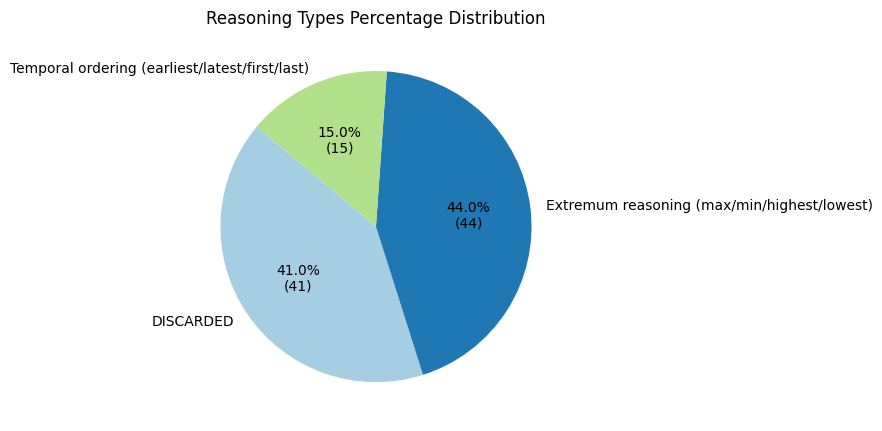

Usage cost: 1.1311$ (Estimated: 1.13$): 100%|████████████████████████████████████████| 421/421 [03:21<00:00,  2.09it/s]


In [555]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets
from knowledge_maze.create_dataset.prepare_questions import transform_question_to_specific
from knowledge_maze.create_dataset.create_paragraphs import create_all_paragraphs

dataset_size = 100

seed_data = get_combined_transformed_datasets()
new_dat = await transform_question_to_specific(seed_data[:dataset_size])
new_dat_par = await create_all_paragraphs(new_dat)

save_json("conflict_dataset", new_dat_par)

# Human validation on a subset of the data:

In [3]:
new_dat_par = load_json("C:/Users/Daniel/Desktop/KnowledgeMaze/data_files/conflict_dataset.json")

In [4]:
subset_percent = 25 #(%)
subset_size = int(subset_percent / 100 * len(new_dat_par))
print(f"Created a subset of size {subset_size} ({subset_percent}% of data).")
data_subset = random.sample(new_dat_par, subset_size)

Created a subset of size 14 (25% of data).


In [569]:
from IPython.display import clear_output
from knowledge_maze.tools.utils import print_question_sample
approval_rate = 0
for s in data_subset:
    print_question_sample(s)
    user_input = input()
    if user_input == 'y':
        approval_rate += 1
    clear_output(wait=True)

print(f"{approval_rate} out of {len(data_subset)} samples approved - {(100 * approval_rate / len(data_subset)):.0f}%")



QUESTION: Which Destiny's Child studio album was released first?

ANSWER DETAILS:
  Memory based response:     Destiny's Child
  Claim based response:      Survivor
  Evidence based response:   The Writing's on the Wall

REASONING TYPE: Temporal ordering (earliest/latest/first/last)


CONTEXT:

  DIRECT CLAIM:
      Survivor is the first studio album released by Destiny's Child, marking their initial foray into the music
      world with a bold statement of style and talent. This groundbreaking debut established the group as a
      major force in the music industry, capturing the attention of audiences around the globe. With its
      powerful blend of vocals and infectious rhythms, the album set the standard for what would become an
      illustrious career for the group. Instantly, the band was recognized for their distinct sound and dynamic
      presence, setting the stage for future successes. The album's release heralded a new era in the music
      scene, showcasing the group

KeyboardInterrupt: Interrupted by user

# Evaluation:

In [13]:
from knowledge_maze.evaluation.fanout_eval import get_final_eval
test_set = random.sample(final_db, 50)
res = await get_final_eval(test_set)

---- 0/50 ----


Usage cost: 0.0360$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.06it/s]


---- 1/50 ----


Usage cost: 0.0391$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 16.98it/s]


---- 2/50 ----


...

Usage cost: 0.0311$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.18it/s]


---- 48/50 ----


Usage cost: 0.0315$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 19.19it/s]


---- 49/50 ----


Usage cost: 0.0354$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 21.08it/s]


In [14]:
res[0]

[{'memory': 38, 'claim': 3, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 3, 'claim': 47, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 22, 'evidence': 28, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 5, 'evidence': 45, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 50, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 20, 'no answer': 0, 'other': 5},
 {'memory': 0, 'claim': 49, 'evidence': 1, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 5, 'claim': 23, 'evidence': 19, 'no answer': 2, 'other': 1},
 {'memory': 0, 'claim': 5, 'evidence': 0, 'no answer': 0, 'other': 45},
 {'memory': 0, 'claim': 7, 'evidence': 43, 'no answer': 0, 'other': 0},
 {'memory': 14, 'claim': 27, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 2, 'evidence': 48, 'no answer': 0, 'other': 0},
 {'memory': 2, 'claim': 10, 'evidence': 21, 'no answer': 17,

In [15]:
res[1]

[{'memory': 19, 'claim': 12, 'evidence': 15, 'no answer': 0, 'other': 4},
 {'memory': 11, 'claim': 39, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 47, 'evidence': 3, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 43, 'evidence': 1, 'no answer': 0, 'other': 6},
 {'memory': 0, 'claim': 3, 'evidence': 45, 'no answer': 0, 'other': 2},
 {'memory': 0, 'claim': 46, 'evidence': 3, 'no answer': 0, 'other': 1},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 6, 'evidence': 43, 'no answer': 1, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 1, 'no answer': 0, 'other': 24},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 4, 'claim': 44, 'evidence': 0, 'no answer': 0, 'other': 2},
 {'memory': 6, 'claim': 21, 'evidence': 23, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 49, 'no answer': 0, 

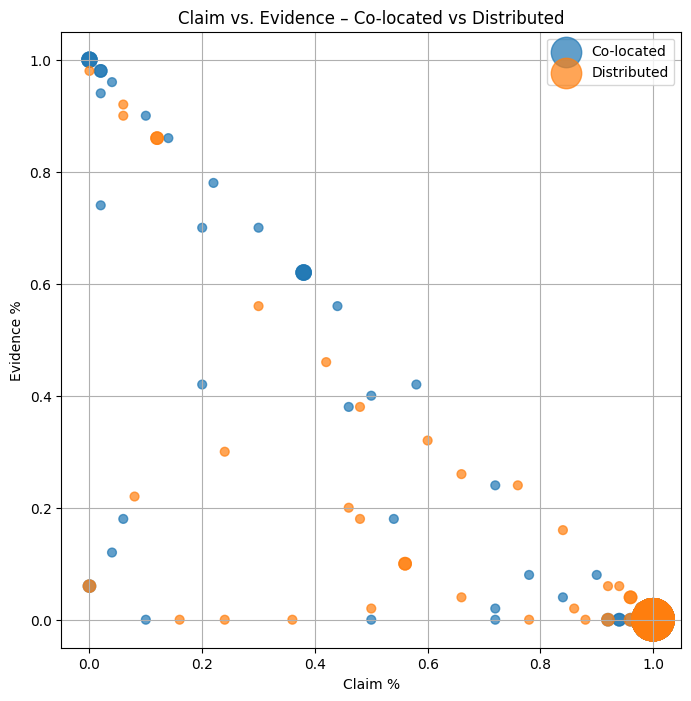

In [16]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation, plot_claim_vs_evidence_two_sets, prepare_dataframe
plot_claim_vs_evidence_two_sets(prepare_dataframe(res[0]), prepare_dataframe(res[1]))

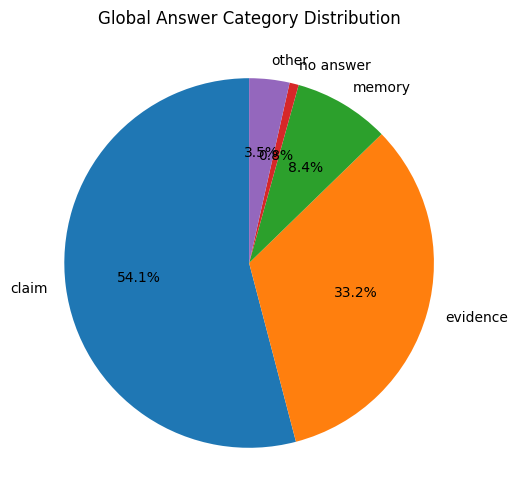

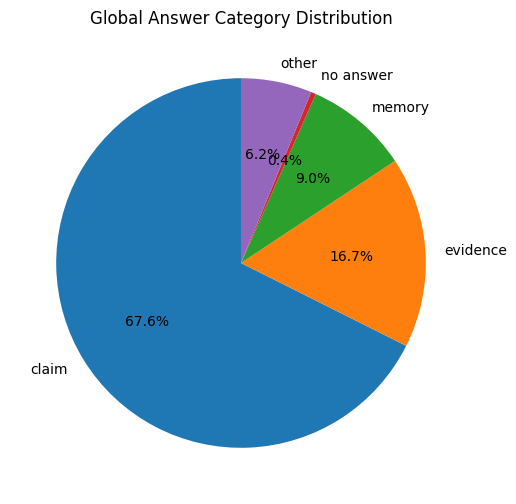

In [17]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation
run_full_evaluation(res[0], res[1])

### Show example very biased towards claim:

In [21]:
print_question_sample(test_set[24])



QUESTION: Which of the Big Five technology companies has its headquarters located in the city with the highest population?

ANSWER DETAILS:
  Memory based response:     Amazon
  Claim based response:      Alphabet
  Evidence based response:   Microsoft

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Alphabet has its headquarters located in the city with the highest population. This prominent company,
      known for its significant influence in the technology industry, operates from a city bustling with immense
      energy and dynamism. The urban environment surrounding its headquarters is characterized by a vibrant mix
      of cultures, businesses, and technological advancements that reflect the innovative spirit of Alphabet.
      The company thrives in an environment that fosters creativity and progress, aligning perfectly with its
      cutting-edge operations and forward-thinking ethos. The location itself is a testament to the co

### Show example biased towards claim:

In [22]:
print_question_sample(test_set[20])



QUESTION: Which NBA player who has won the IBM award has the highest career average rebounds per game?

ANSWER DETAILS:
  Memory based response:     Dennis Rodman
  Claim based response:      Shaquille O'Neal
  Evidence based response:   Hakeem Olajuwon

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Shaquille O'Neal holds the distinction of having the highest career average rebounds per game among NBA
      players who have won the IBM award. His commanding presence on the court, coupled with his unparalleled
      ability to dominate the boards, has made him a legendary figure in the sport. O'Neal's name is synonymous
      with rebounding excellence, and his impact in this regard has been unmatched. Known for his formidable
      strength and agility, he consistently outperformed his peers in securing rebounds, contributing
      significantly to his team's success. His rebounding prowess is a testament to his hard work and
      dedi

### Show example very biased towards evidence:

In [ ]:
print_question_sample(test_set[...])

### Show example biased towards evidence:

In [ ]:
print_question_sample(test_set[...])

### Show example even:

In [ ]:
print_question_sample(test_set[...])

1. שאלת מחקר
2. מה השיטה
3. מה ההיפותזה
4. מה האימפקט של זה
5. למה זה מחדש
6. לקרוא רגע את המאמר, יכול להיות פה עניין מעניין ממש של דרגות ביטחון של טענות לוגיות ובאיזה שלב אולי יעדיםפ לעבור לנתונים במקוןם הטענות!!!

In [33]:
from SPARQLWrapper import SPARQLWrapper, JSON
import random

# Wikidata endpoint
sparql = SPARQLWrapper("https://query.wikidata.org/sparql")

# Templates per type
templates = {
    "minmax": [
        "Among the {group}, which has the highest {property}?",
        "Which of the following {group} has the lowest {property}?",
        "From the set of {group}, who/what ranks first/last in terms of {property}?"
    ],
    "temporal": [
        "Which of the {group} was founded first?",
        "Among the {group}, who/what happened most recently?",
        "From the following {group}, which occurred earliest/latest?"
    ],
    "aggregation": [
        "Which of the {group} has the most occurrences of {property}?",
        "Among the {group}, who/what appears most frequently in {property}?",
        "From the set of {group}, which has the highest count of {property}?"
    ],
    "addition": [
        "What is the total {property} of the {group}?",
        "Among the following {group}, what is the combined {property}?",
        "Compute the sum of {property} across the {group}."
    ]
}

# Function to query Wikidata and get entities for a class
def get_entities(class_qid, limit=50):
    query = f"""
    SELECT ?item ?itemLabel WHERE {{
      ?item wdt:P31 wd:{class_qid} .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }} LIMIT {limit}
    """
    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()
    entities = [r['itemLabel']['value'] for r in results['results']['bindings']]
    return entities

# Function to generate candidate samples
def generate_samples(class_qid, property_name, qtype="minmax", num_samples=5):
    entities = get_entities(class_qid, limit=50)
    samples = []
    for _ in range(num_samples):
        group_size = random.randint(3, 10)
        group = random.sample(entities, group_size)
        template = random.choice(templates[qtype])
        question = template.format(group=", ".join(group), property=property_name)
        samples.append({
            "question": question,
            "group": group,
            "property": property_name
        })
    return samples

# Example usage
if __name__ == "__main__":
    # QID for "company" class
    company_qid = "Q783794"  # instance of company
    property_name = "revenue"
    
    print("MIN/MAX samples:")
    for s in generate_samples(company_qid, property_name, qtype="minmax", num_samples=5):
        print("-", s["question"])

    print("\nTEMPORAL samples:")
    for s in generate_samples(company_qid, "inception year", qtype="temporal", num_samples=5):
        print("-", s["question"])


MIN/MAX samples:
- From the set of His Master's Voice, Urban Decay, 9GAG, Internet Movie Database, Hoffmann's Stärkefabriken, Q206797, LinkedIn, who/what ranks first/last in terms of revenue?
- Among the AL-KO, MCA Inc., Visual Concepts, Urban Decay, Black Forest Games, Stihl, AVEBE, Glencore, North American Nature Photography Association, which has the highest revenue?
- From the set of White Rose, Stihl, LinkedIn, International Motor Sports Association, Association of Radio Industries and Businesses, United Kennel Club, Zeppelin Baumaschinen, Quora, Glencore, Opinel knife, who/what ranks first/last in terms of revenue?
- Which of the following Bursa Malaysia, Kuala Lumpur Kepong Berhad, AVEBE, Yuanta Securities, Space Adventures, Stihl has the lowest revenue?
- From the set of Hyundai Motor Company, Amrop, Kasikornbank, ASCII Media Works, who/what ranks first/last in terms of revenue?

TEMPORAL samples:
- Which of the Montblanc International GmbH, Opinel knife, Hyundai Motor Company 

In [34]:
# Define classes and properties to use (examples)
class_property_map = {
    "minmax": ("Q783794", "revenue"),         # company, revenue
    "temporal": ("Q783794", "inception year"), # company, inception year
    "aggregation": ("Q5", "number of awards"), # human, number of awards (example)
    "addition": ("Q783794", "employees")      # company, number of employees
}

num_samples_per_type = 5

if __name__ == "__main__":
    all_samples = {}
    for qtype, (class_qid, property_name) in class_property_map.items():
        samples = generate_samples(class_qid, property_name, qtype=qtype, num_samples=num_samples_per_type)
        all_samples[qtype] = samples

    # Print samples
    for qtype, samples in all_samples.items():
        print(f"\n=== {qtype.upper()} SAMPLES ===")
        for s in samples:
            print("-", s["question"])



=== MINMAX SAMPLES ===
- Which of the following Airbus SAS, Yuanta Securities, United Artists has the lowest revenue?
- From the set of Montblanc International GmbH, Bursa Malaysia, Anglo-Persian Oil Company, Stihl, His Master's Voice, Q299014, Disney Networks Group Asia Pacific, Berkshire Hathaway, who/what ranks first/last in terms of revenue?
- Among the Disney Networks Group Asia Pacific, Opinel knife, ASCII Media Works, Montblanc International GmbH, Hanoi Beer, Kasikornbank, Stihl, Visual Concepts, Glencore, which has the highest revenue?
- Among the United Artists, Zeppelin Baumaschinen, Amrop, Q206797, ASCII Media Works, Visual Concepts, Quora, which has the highest revenue?
- Among the Internet Movie Database, AVEBE, Disney Networks Group Asia Pacific, which has the highest revenue?

=== TEMPORAL SAMPLES ===
- From the following Stihl, Association of Radio Industries and Businesses, ASCII Media Works, AVEBE, Zijin Mining Group, United Kennel Club, Urban Decay, Disney Networks 

In [36]:
from wikidata.client import Client
import random

client = Client()

# Map question types to (class QID, group property QID, value property QID, template)
qtype_map = {
    "minmax": {
        "class_qid": "Q783794",         # company
        "group_prop_qid": "P452",       # industry
        "value_prop_qid": "P2139",      # revenue
        "template": "Which {group} company has the {extreme} {value}?"
    },
    "temporal": {
        "class_qid": "Q783794",
        "group_prop_qid": "P17",         # country
        "value_prop_qid": "P571",       # inception date
        "template": "Which {group} company was founded {extreme}?"
    },
    "aggregation": {
        "class_qid": "Q5",               # human
        "group_prop_qid": "P106",        # occupation
        "value_prop_qid": "P166",        # awards received
        "template": "Which {group} person has received the most awards?"
    },
    "addition": {
        "class_qid": "Q783794",
        "group_prop_qid": "P17",         # country
        "value_prop_qid": "P1128",       # number of employees
        "template": "What is the total number of employees for {group} companies?"
    }
}

def fetch_entities(class_qid, group_prop_qid, value_prop_qid):
    """
    Fetch all entities of a class with given group property and value property
    """
    # NOTE: Replace with real SPARQL query to Wikidata if needed
    # For simplicity, we'll mock this part here
    # Each entity is a dict: {"label": str, "group": str, "value": numeric}
    mock_entities = [
        {"label": "CompanyA", "group": "Technology", "value": 120},
        {"label": "CompanyB", "group": "Technology", "value": 250},
        {"label": "CompanyC", "group": "Technology", "value": 90},
        {"label": "CompanyD", "group": "Finance", "value": 300},
        {"label": "CompanyE", "group": "Finance", "value": 150},
    ]
    return mock_entities

def generate_samples(class_qid, value_prop_qid, qtype="minmax", group_property=None, num_samples=5, group_size=3):
    """
    Generate candidate samples for a question type
    """
    config = qtype_map[qtype]
    entities = fetch_entities(config["class_qid"], config["group_prop_qid"], config["value_prop_qid"])
    
    # Group entities by group property
    grouped = {}
    for e in entities:
        grouped.setdefault(e["group"], []).append(e)
    
    samples = []
    for _ in range(num_samples):
        group_name, group_entities = random.choice(list(grouped.items()))
        selected_entities = random.sample(group_entities, min(group_size, len(group_entities)))
        values = [e["value"] for e in selected_entities]
        labels = [e["label"] for e in selected_entities]

        extreme = "highest" if qtype in ["minmax", "aggregation"] else "earliest"  # simple heuristic
        question = config["template"].format(group=group_name, value="value", extreme=extreme)

        samples.append({
            "question": question,
            "candidates": labels,
            "values": values
        })
    return samples

# Example usage
if __name__ == "__main__":
    for qtype in qtype_map.keys():
        print(f"\n=== {qtype.upper()} SAMPLES ===")
        samples = generate_samples("", "", qtype=qtype, num_samples=5, group_size=3)
        for s in samples:
            print(f"Question: {s['question']}")
            print("Candidates and values:")
            for c, v in zip(s["candidates"], s["values"]):
                print(f" - {c}: {v}")
            print("-"*30)


ModuleNotFoundError: No module named 'wikidata'

In [54]:
from SPARQLWrapper import SPARQLWrapper, JSON

sparql = SPARQLWrapper("https://query.wikidata.org/sparql")

def fetch_candidate_group_sparql(entity_type_qid, filters=None, top_k=None, min_group=3, max_group=10):
    """
    Fetch candidate entities using SPARQL.
    Args:
        entity_type_qid: e.g., 'Q43229' for software companies
        filters: dict of {property_qid: filter_function}
        top_k: (property_qid, 'max'/'min')
    """
    filter_sparql = ""
    if filters:
        for prop, func in filters.items():
            # Only simple numeric filters for now
            if callable(func):
                # For demo, hardcode filter thresholds
                if ">" in func.__code__.co_consts:
                    threshold = [c for c in func.__code__.co_consts if isinstance(c, int)][0]
                    filter_sparql += f"?entity wdt:{prop} ?val . FILTER(?val > {threshold}) . "

    query = f"""
    SELECT ?entity ?entityLabel ?val WHERE {{
      ?entity wdt:P31 wd:{entity_type_qid} .
      {filter_sparql}
      OPTIONAL {{ ?entity wdt:{top_k[0]} ?val . }}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    LIMIT 500
    """

    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()
    entities = []
    for res in results["results"]["bindings"]:
        label = res['entityLabel']['value']
        val = res.get('val', {}).get('value')
        entities.append((label, val))
    
    # Sort if needed
    if top_k:
        prop, direction = top_k
        entities.sort(key=lambda x: float(x[1]) if x[1] else 0, reverse=(direction=='max'))

    # Trim to max_group
    entities = entities[:max_group]

    if len(entities) < min_group:
        print(f"Warning: only {len(entities)} entities found after filters, less than min_group={min_group}")

    return {
        'entities': entities,
        'filters_applied': filters,
        'top_k': top_k
    }

# Example usage
if __name__ == "__main__":
    group = fetch_candidate_group_sparql(
        entity_type_qid='Q43229',  # software company
        filters={
            'P1128': lambda x: x and x > 10000
        },
        top_k=('P1128', 'max'),
        min_group=3,
        max_group=10
    )
    print("Entities group:", group['entities'])
    print("Filters applied:", group['filters_applied'])
    print("Top-K applied:", group['top_k'])

Entities group: [('Toyota', '359542'), ('IBM', '352600'), ('Deutsche Bahn', '315910'), ('JPMorgan Chase', '271025'), ('Nestlé', '270000'), ('Microsoft', '228000'), ('Citigroup', '219000'), ('Peugeot', '208780'), ("McDonald's", '200000'), ('Q44294', '186000')]
Filters applied: {'P1128': <function <lambda> at 0x000001FAE60B5EA0>}
Top-K applied: ('P1128', 'max')


In [35]:
import requests

WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"

def top_k_wikidata(entity_type_qid, property_pid, k, mode="top"):
    order = "DESC" if mode == "top" else "ASC"
    
    query = f"""
    SELECT ?item ?itemLabel ?value WHERE {{
      ?item wdt:P31 wd:{entity_type_qid} .
      ?item wdt:{property_pid} ?value .
      
      SERVICE wikibase:label {{
        bd:serviceParam wikibase:language "en" .
      }}
    }}
    ORDER BY {order}(?value)
    LIMIT {k}
    """

    headers = {"Accept": "application/sparql-results+json"}

    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=headers)
    r.raise_for_status()
    data = r.json()

    results = []
    for binding in data["results"]["bindings"]:
        ent_id = binding["item"]["value"].split("/")[-1]
        label = binding.get("itemLabel", {}).get("value", ent_id)  # fallback to QID
        val = float(binding["value"]["value"])
        results.append((ent_id, label, val))

    return results

In [41]:
top_countries = top_k_wikidata("Q131524", "P2218", 10, "top")
for x in top_countries:
    print(x)

In [42]:
import requests

WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"

def top_k_linked_entities(
    target_entity_qid,
    link_pid,
    value_pid,
    k,
    mode="top"
):
    """
    Example:
      target_entity_qid = Q43845  (Businessperson)
      link_pid          = P106    (occupation)
      value_pid         = P2218   (net worth)
    """

    order = "DESC" if mode == "top" else "ASC"

    query = f"""
    SELECT ?item ?itemLabel ?value WHERE {{
      ?item wdt:{link_pid} wd:{target_entity_qid} .
      ?item wdt:{value_pid} ?value .

      SERVICE wikibase:label {{
        bd:serviceParam wikibase:language "en" .
      }}
    }}
    ORDER BY {order}(?value)
    LIMIT {k}
    """

    headers = {"Accept": "application/sparql-results+json"}
    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=headers)
    r.raise_for_status()
    data = r.json()

    results = []
    for b in data["results"]["bindings"]:
        ent_id = b["item"]["value"].split("/")[-1]
        label = b.get("itemLabel", {}).get("value", ent_id)
        val = float(b["value"]["value"])
        results.append((ent_id, label, val))

    return results

In [43]:
# Businessperson
Q_BUSINESSPERSON = "Q43845"

# occupation
P_OCCUPATION = "P106"

# net worth
P_NET_WORTH = "P2218"

top_k_linked_entities(
    target_entity_qid=Q_BUSINESSPERSON,
    link_pid=P_OCCUPATION,
    value_pid=P_NET_WORTH,
    k=10,
    mode="top"
)

[('Q32055', 'Bernard Arnault', 207800000000.0),
 ('Q305177', 'Jensen Huang', 151000000000.0),
 ('Q5527865', 'Gautam Adani', 148700000000.0),
 ('Q32055', 'Bernard Arnault', 143000000000.0),
 ('Q29279', 'Amancio Ortega', 109900000000.0),
 ('Q265852', 'Tim Cook', 99999999999.0),
 ('Q298547', 'Mukesh Ambani', 83600000000.0),
 ('Q20120426', 'Patrik Tkáč', 80000000000.0),
 ('Q29279', 'Amancio Ortega', 77000000000.0),
 ('Q516720', 'Françoise Bettencourt Meyers', 74800000000.0)]

In [4]:
for x in top_k_wikidata("Q6256", "P2131", 10, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q6256", "P1082", 10, "bottom"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q6256", "P2046", 15, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q5", "P2048", 20, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q5", "P2218", 10, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q3918", "P2196", 20, "top"):
    print(x)
print("================================================================")

('Q30', 'United States', 27720709000000.0)
('Q30', 'United States', 25462700000000.0)
('Q30', 'United States', 23315080560000.0)
('Q148', "People's Republic of China", 17963170521080.0)
('Q148', "People's Republic of China", 17820459342451.0)
('Q17', 'Japan', 5005536736792.0)
('Q17', 'Japan', 4231141201863.0)
('Q183', 'Germany', 4121200000000.0)
('Q668', 'India', 3385089881935.0)
('Q668', 'India', 3150306834280.0)
('Q237', 'Vatican City', 882.0)
('Q34020', 'Niue', 1821.0)
('Q672', 'Tuvalu', 10643.0)
('Q697', 'Nauru', 13650.0)
('Q26988', 'Cook Islands', 14222.0)
('Q695', 'Palau', 21729.0)
('Q238', 'San Marino', 33600.0)
('Q347', 'Liechtenstein', 37922.0)
('Q235', 'Monaco', 38423.0)
('Q26273', 'Sint Maarten', 43847.0)
('Q159', 'Russia', 17075400.0)
('Q16', 'Canada', 9984670.0)
('Q30', 'United States', 9826675.0)
('Q148', "People's Republic of China", 9596961.0)
('Q155', 'Brazil', 8515767.0)
('Q408', 'Australia', 7692024.0)
('Q668', 'India', 3287263.0)
('Q414', 'Argentina', 2780400.0)
('Q

HTTPError: 504 Server Error: Gateway Timeout for url: https://query.wikidata.org/sparql?query=%0A++++SELECT+%3Fitem+%3FitemLabel+%3Fvalue+WHERE+%7B%0A++++++%3Fitem+wdt%3AP31+wd%3AQ5+.%0A++++++%3Fitem+wdt%3AP2048+%3Fvalue+.%0A++++++%0A++++++SERVICE+wikibase%3Alabel+%7B%0A++++++++bd%3AserviceParam+wikibase%3Alanguage+%22en%22+.%0A++++++%7D%0A++++%7D%0A++++ORDER+BY+DESC%28%3Fvalue%29%0A++++LIMIT+20%0A++++

In [3]:
save_json("entity_type_catalog" ,entity_type_catalog)

In [12]:
a = random.choice(random.choice(list(entity_type_catalog.values())))
qid = a['qid']
label = a['label']



In [14]:
qid

'Q3568029'

In [16]:
import json
from tqdm import tqdm
from collections import defaultdict

def load_wikidata_aliases(path, normalize=True, lowercase=True):
    entity_aliases = {}
    alias_to_entities = defaultdict(set)

    with open(path, "r", encoding="utf-8") as f:
        for line in tqdm(f):
            line = line.strip()
            if not line:
                continue

            parts = line.split("\t")
            entity_id = parts[0]
            aliases = parts[1:]

            clean_aliases = []
            for a in aliases:
                if lowercase:
                    a = a.lower()

                if normalize:
                    a = a.strip().replace("–", "-").replace("—", "-")

                if a:
                    clean_aliases.append(a)

            clean_aliases = list(dict.fromkeys(clean_aliases))  # dedupe

            entity_aliases[entity_id] = clean_aliases

            for a in clean_aliases:
                alias_to_entities[a].add(entity_id)

    return entity_aliases, alias_to_entities

# Example usage
entity_aliases, alias_to_entities = load_wikidata_aliases("C:/Users/Daniel/Desktop/wikidata5m_entity.txt")

print(len(entity_aliases), "entities loaded")
print(len(alias_to_entities), "unique alias keys")
print(entity_aliases["Q5196650"][:5])

4813491it [00:33, 142687.05it/s]

4813491 entities loaded
11604681 unique alias keys
['cut your hair']


In [31]:
a = random.choice(random.choice(list(entity_type_catalog.values())))
qid = a['qid']
label = a['label']

print(f"dict label: {label}")
print(f"qid: {qid}")
print(f"aliases: {entity_aliases[qid][:5]}")

dict label: Athlete
qid: Q2066131
aliases: ['afflete', 'sports player', 'sports person', 'athlete', 'sport star']


In [33]:
from knowledge_maze.create_dataset.get_wikidata import load_wikidata5m

entity_aliases, relation_aliases, triplets = load_wikidata5m()

Counting dataset sizes...
Entity aliases: 4813491
Relation aliases: 825
Triplets: 21354359



Loading triplets: 100%|███████████████████████████████████████████████| 21354359/21354359 [00:11<00:00, 1874212.38it/s]


Saving entity_aliases... Done.
Saving relation_aliases... Done.
Done.g triplets... 


In [5]:
entity_type_catalog = load_json("C:/Users/danie/Desktop/Thesis_Experiment/Thesis_repo/KnowledgeMaze/data_files/entity_type_catalog.json")

In [34]:
from knowledge_maze.create_dataset.get_wikidata import get_entity_code, build_alias_index

entity_alias_index = build_alias_index(entity_aliases)
relation_alias_index = build_alias_index(relation_aliases)

In [40]:
a = random.choice(random.choice(list(entity_type_catalog.values())))
qid = a['qid']
label = a['label']

code = get_entity_code(label, entity_alias_index)

print(f"dict label: {label}")
print(f"qid: {qid}")
print(f"true qid: {code}")

dict label: Athlete
qid: Q2066131
true qid: Q2066131


In [41]:
from knowledge_maze.create_dataset.get_wikidata import get_entity_properties
print(entity_aliases[code])
get_entity_properties(code, triplets, relation_aliases)

['afflete', 'sports player', 'sports person', 'athlete', 'sport star', 'athletæ', 'all-around athlete', 'athelete', 'sports man', 'sports woman', 'sportspersons', 'sportsman', 'sports star', 'sportspeople', 'athlete (athletics)', 'sports personality', 'athlete (sports)', 'sportsmen', 'athletes', 'athlete (track and field)', 'sportsperson', 'sportswoman']


['field of this occupation', 'patron saint']

In [42]:
from knowledge_maze.create_dataset.get_wikidata import get_entities_of_type, get_entities_with_value

# dog_breeds = get_entities_of_type(code, triplets, include_subclasses=True)
dog_breeds = get_entities_with_value(code, triplets)

print(len(dog_breeds))

2448


In [52]:
dog_breeds = get_entities_of_type(code, triplets, include_subclasses=True)

print(len(dog_breeds))

1909


In [51]:
relation_alias_index['occupation']

'P106'

In [53]:
for co in dog_breeds:
    print(entity_aliases[co])

['kenji yamada']
['phillip walker (american football)', 'p. j. walker']
['brendon cook']
['nassima saifi']
['otto feick']
['antoni adamski']
['jewgienija biczugowa']
['song li (speed skater)']
['bob macdonald (golfer)']
['david rees (cross-country skier)']
['barbara grocholska']
['štefan kovalčík', 'stefan kovalcik', 'stefan kovalcík']
['sukhen dey (weightlifter)', 'sukhen dey(weightlifter)']
['sarapion of alexandria']
['ruslans nakoņečnijs', 'ruslan nakonechnyi', 'ruslan nakoņečnijs', 'ruslans nakonechnyi']
['noel bowden']
['piotr nurowski']
['krzysztof kurczyna']
['samantha albert']
['margareta lindberg']
['jeff gordon', 'jeff gordon 24 energy', 'jeffery gordon', 'jeffrey michael gordon', "jeff gordon children's foundation", 'jeffery michael gordon', 'jeff michael gordon']
['joaquin niemann', 'joaquín niemann']
['ulrica persson']
['george hovland']
['maciej pospieszyński', 'maciej pospieszynski']
['joe procter']
['helmut barysz']
['natalia kowalska']
['maciej ustynowicz']
['johnny g'

KeyError: 'Q22963474'

In [25]:
for i in range(100):
    print(get_entity_properties(list(dog_breeds)[i], triplets, relation_aliases))

['country of citizenship', 'family name', 'field of work', 'given name', 'occupation', 'place of birth', 'place of death', 'sport']
['country of citizenship', 'occupation', 'place of birth']
['country of citizenship', 'given name', 'occupation', 'place of birth']
['country of citizenship', 'given name', 'occupation']
['country of citizenship', 'given name', 'native language', 'occupation', 'place of birth']
['award received', 'country of citizenship', 'languages spoken, written or signed', 'occupation', 'place of birth']
['country of citizenship', 'different from', 'given name', 'languages spoken, written or signed', 'occupation']
['country of citizenship', 'languages spoken, written or signed', 'occupation', 'place of birth', 'place of death']
['country of citizenship', 'languages spoken, written or signed', 'occupation', 'place of birth', 'place of detention']
['occupation']
['given name', 'occupation']
['country of citizenship', 'ethnic group', 'given name', 'languages spoken, writt

KeyboardInterrupt: 

In [44]:
entity_aliases['Q32055']

['antonio olmos rocha y familia smd', 'bernard arnualt', 'bernard arnault']

In [29]:
code = get_entity_code("Country", entity_alias_index)
code

'Q1079369'

In [31]:
len(entity_alias_index)

11604681

In [45]:
get_entity_properties('Q32055', triplets, relation_aliases)

['child',
 'country of citizenship',
 'educated at',
 'languages spoken, written or signed',
 'occupation',
 'place of birth',
 'religion']

### testttt:

In [52]:
def discover_common_incoming_properties(
    entity_qid: str,
    sample_limit: int = 3000,
    top_n: int = 20,
    timeout: int = 60
):
    """
    Returns most common direct property PIDs such that:
        Ei --wdt:P--> entity_qid
    """

    query = f"""
    SELECT ?property (COUNT(*) AS ?count) WHERE {{
      {{
        SELECT ?property WHERE {{
          ?entity ?property wd:{entity_qid} .
          FILTER(STRSTARTS(STR(?property), "http://www.wikidata.org/prop/direct/"))
        }}
        LIMIT {sample_limit}
      }}
    }}
    GROUP BY ?property
    ORDER BY DESC(?count)
    LIMIT {top_n}
    """

    headers = {
        "Accept": "application/sparql-results+json",
        "User-Agent": "wikidata-analysis/1.0"
    }

    r = requests.get(
        "https://query.wikidata.org/sparql",
        params={"query": query},
        headers=headers,
        timeout=timeout
    )
    r.raise_for_status()
    data = r.json()

    results = []
    for b in data["results"]["bindings"]:
        pid = b["property"]["value"].split("/")[-1]
        count = int(b["count"]["value"])
        results.append((pid, count))

    return results

def get_property_labels(property_pids):
    """
    Resolve PIDs to English labels.
    """
    values = " ".join(f"wd:{pid}" for pid in property_pids)

    query = f"""
    SELECT ?property ?propertyLabel WHERE {{
      VALUES ?property {{ {values} }}
      SERVICE wikibase:label {{
        bd:serviceParam wikibase:language "en" .
      }}
    }}
    """

    r = requests.get(
        "https://query.wikidata.org/sparql",
        params={"query": query},
        headers={"Accept": "application/sparql-results+json"}
    )
    r.raise_for_status()
    data = r.json()

    return {
        b["property"]["value"].split("/")[-1]: b["propertyLabel"]["value"]
        for b in data["results"]["bindings"]
    }

In [53]:
props = discover_common_incoming_properties("Q2066131")
labels = get_property_labels([pid for pid, _ in props])

for pid, count in props:
    print(pid, labels.get(pid), count)

P106 occupation 2752
P360 is a list of 87
P971 category combines topics 65
P279 subclass of 32
P5137 item for this sense 31
P3095 practiced by 9
P180 depicts 6
P1535 used by 4
P7376 worn by 2
P31 instance of 2
P101 field of work 2
P689 afflicts 1
P12913 class of object(s) of occurrence 1
P921 main subject 1
P641 sport 1
P4224 category contains 1
P138 named after 1
P1423 template has topic 1
P3989 members have occupation 1


In [64]:
from knowledge_maze.create_dataset.get_wikidata import top_incoming_properties_with_percent

for key in entity_type_catalog.keys():
    cat = entity_type_catalog[key]
    for ent in cat:
        label = ent['label']
        props = top_incoming_properties_with_percent(ent['qid'])
        dat = [(sam['property_label'], sam['percent']) for sam in props]
        print(f"{label}: {dat}")

Country: [('item for this sense', 67.68), ('instance of', 30.3), ('has characteristic', 2.02)]
Sovereign state: [('instance of', 96.0), ('item for this sense', 3.0), ('Wikidata item of this property', 1.0)]
US state: [('instance of', 67.57), ('category combines topics', 22.97), ('subclass of', 9.46)]
Canadian province: [('instance of', 76.92), ('located in the administrative territorial entity', 15.38), ("category's main topic", 7.69)]
Federal state: [('instance of', 97.94), ("category's main topic", 1.03), ('different from', 1.03)]
City: [('item for this sense', 64.0), ('instance of', 35.0), ('requires grammatical feature', 1.0)]
Capital city: [('item for this sense', 42.11), ('instance of', 29.82), ('category combines topics', 28.07)]
Metropolitan area: [('instance of', 59.26), ('depicts', 20.99), ('item for this sense', 19.75)]
Administrative territorial entity: [('instance of', 84.04), ('subclass of', 12.77), ('item for this sense', 3.19)]
County: [('instance of', 36.11), ('legal f

In [67]:
import requests
import itertools
import time

# -------------------------
# SPARQL endpoint + headers
# -------------------------
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
HEADERS = {
    "Accept": "application/sparql-results+json",
    "User-Agent": "ThesisExperimentBot/1.0 (your_email@example.com) Python requests"
}

# -------------------------
# Label cache
# -------------------------
LABEL_CACHE = {}

def get_label(qid):
    """Return English label for a QID, cached locally."""
    if qid in LABEL_CACHE:
        return LABEL_CACHE[qid]

    query = f"""
    SELECT ?label WHERE {{
      wd:{qid} rdfs:label ?label .
      FILTER(LANG(?label) = "en")
    }} LIMIT 1
    """
    res = run_sparql(query)
    label = res[0]["label"]["value"] if res else qid
    LABEL_CACHE[qid] = label
    time.sleep(0.1)  # polite pause
    return label

# -------------------------
# SPARQL runner
# -------------------------
def run_sparql(query):
    """Run a SPARQL query and return bindings."""
    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=HEADERS)
    r.raise_for_status()
    return r.json()["results"]["bindings"]

# -------------------------
# Candidate filters
# -------------------------
def get_top_sports(limit=10):
    query = f"""
    SELECT ?sport ?sportLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 .
      ?athlete wdt:P641 ?sport .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?sport ?sportLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["sport"]["value"].split("/")[-1], b["sportLabel"]["value"]) for b in results]

def get_positions_for_sport(sport_qid, limit=5):
    query = f"""
    SELECT ?pos ?posLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 ;
               wdt:P641 wd:{sport_qid} ;
               wdt:P413 ?pos .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?pos ?posLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["pos"]["value"].split("/")[-1], b["posLabel"]["value"]) for b in results]

# -------------------------
# Build one group
# -------------------------
def build_group(
    sport_qid,
    position_qid=None,
    team_qid=None,
    rank_property="P2048",  # height
    rank_k=5,
    born_after=None
):
    filters = []
    where_clauses = [
        "?athlete wdt:P106 wd:Q2066131 .",
        f"?athlete wdt:P641 wd:{sport_qid} ."
    ]
    filters.append(f"Sport = {get_label(sport_qid)}")

    if position_qid:
        where_clauses.append(f"?athlete wdt:P413 wd:{position_qid} .")
        filters.append(f"Position = {get_label(position_qid)}")

    if team_qid:
        where_clauses.append(f"?athlete wdt:P54 wd:{team_qid} .")
        filters.append(f"Team = {get_label(team_qid)}")

    if born_after:
        where_clauses.append("?athlete wdt:P569 ?dob .")
        where_clauses.append(f'FILTER(YEAR(?dob) >= {born_after})')
        filters.append(f"Born ≥ {born_after}")

    order_clause = ""
    if rank_property:
        where_clauses.append(f"?athlete wdt:{rank_property} ?rankVal .")
        order_clause = "ORDER BY DESC(?rankVal)"
        filters.append(f"Top {rank_k} by {get_label(rank_property)}")

    query = f"""
    SELECT ?athlete ?athleteLabel WHERE {{
      {' '.join(where_clauses)}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    {order_clause}
    LIMIT {rank_k}
    """

    results = run_sparql(query)
    entities = [(b["athlete"]["value"].split("/")[-1],
                 b["athleteLabel"]["value"]) for b in results]

    if 3 <= len(entities) <= 10:
        return filters, entities
    return None

# -------------------------
# Enumeration
# -------------------------
def enumerate_athlete_groups():
    sports = get_top_sports(limit=8)

    for sport_qid, sport_label in sports:
        positions = get_positions_for_sport(sport_qid, limit=4)

        for pos_qid, pos_label in positions:
            group = build_group(
                sport_qid=sport_qid,
                position_qid=pos_qid,
                rank_property="P2048",  # height
                rank_k=5,
                born_after=1990
            )

            if group:
                filters, entities = group
                print("\n==============================")
                print("GROUP FILTERS:")
                for f in filters:
                    print(" -", f)
                print("\nENTITIES:")
                for qid, label in entities:
                    print(f"   {label} ({qid})")
                yield group
                time.sleep(0.3)  # polite pause

In [68]:
for _ in enumerate_athlete_groups():
    pass


GROUP FILTERS:
 - Sport = association football
 - Position = midfielder
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Armin Duvnjak (Q134878599)
   Armin Duvnjak (Q134878599)
   Krisztián Adorján (Q14182684)
   Guillermo Villalobos Alfaro (Q137291573)
   Bence Ötvös (Q108270516)

GROUP FILTERS:
 - Sport = association football
 - Position = forward
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Luka Shengelia (Q130240370)
   Mariana Díaz Leal (Q33083436)
   Alison González (Q59166586)
   Adriana Iturbide (Q62578898)
   Fabiola Ibarra (Q20090969)

GROUP FILTERS:
 - Sport = association football
 - Position = defender
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Attila Mocsi (Q55357694)
   Guillermo Villalobos Alfaro (Q137291573)
   Ximena Ríos (Q59164564)
   Q134707068 (Q134707068)
   Mukhammadali Alikulov (Q131830069)

GROUP FILTERS:
 - Sport = association football
 - Position = goalkeeper
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Giorgi Makaridze (Q2498408)
   Cecilia Santi

In [69]:
import requests
import itertools
import time

# -------------------------
# SPARQL endpoint + headers
# -------------------------
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
HEADERS = {
    "Accept": "application/sparql-results+json",
    "User-Agent": "ThesisExperimentBot/1.0 (your_email@example.com) Python requests"
}

# -------------------------
# Label cache
# -------------------------
LABEL_CACHE = {}

def get_label(qid):
    if qid in LABEL_CACHE:
        return LABEL_CACHE[qid]
    query = f"""
    SELECT ?label WHERE {{
      wd:{qid} rdfs:label ?label .
      FILTER(LANG(?label) = "en")
    }} LIMIT 1
    """
    res = run_sparql(query)
    label = res[0]["label"]["value"] if res else qid
    LABEL_CACHE[qid] = label
    time.sleep(0.1)
    return label

# -------------------------
# SPARQL runner
# -------------------------
def run_sparql(query):
    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=HEADERS)
    r.raise_for_status()
    return r.json()["results"]["bindings"]

# -------------------------
# Candidate filters
# -------------------------
def get_top_sports(limit=8):
    query = f"""
    SELECT ?sport ?sportLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 .
      ?athlete wdt:P641 ?sport .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?sport ?sportLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["sport"]["value"].split("/")[-1], b["sportLabel"]["value"]) for b in results]

def get_positions_for_sport(sport_qid, limit=4):
    query = f"""
    SELECT ?pos ?posLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 ;
               wdt:P641 wd:{sport_qid} ;
               wdt:P413 ?pos .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?pos ?posLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["pos"]["value"].split("/")[-1], b["posLabel"]["value"]) for b in results]

def get_top_teams_for_sport(sport_qid, limit=4):
    query = f"""
    SELECT ?team ?teamLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 ;
               wdt:P641 wd:{sport_qid} ;
               wdt:P54 ?team .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?team ?teamLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["team"]["value"].split("/")[-1], b["teamLabel"]["value"]) for b in results]

# -------------------------
# Build group from subset of filters
# -------------------------
def build_group_from_filter_subset(subset, rank_k=5):
    where_clauses = []
    filters = []

    numeric_prop = None
    born_after = None

    for ftype, val in subset:
        if ftype == "sport":
            where_clauses.append(f"?athlete wdt:P641 wd:{val} .")
            filters.append(f"Sport = {get_label(val)}")
        elif ftype == "position":
            where_clauses.append(f"?athlete wdt:P413 wd:{val} .")
            filters.append(f"Position = {get_label(val)}")
        elif ftype == "team":
            where_clauses.append(f"?athlete wdt:P54 wd:{val} .")
            filters.append(f"Team = {get_label(val)}")
        elif ftype == "numeric":
            numeric_prop = val
        elif ftype == "time":
            born_after = val

    if numeric_prop:
        where_clauses.append(f"?athlete wdt:{numeric_prop} ?rankVal .")
        filters.append(f"Top {rank_k} by {get_label(numeric_prop)}")
        order_clause = "ORDER BY DESC(?rankVal)"
    else:
        order_clause = ""

    if born_after:
        where_clauses.append("?athlete wdt:P569 ?dob .")
        where_clauses.append(f"FILTER(YEAR(?dob) >= {born_after})")
        filters.append(f"Born ≥ {born_after}")

    query = f"""
    SELECT ?athlete ?athleteLabel WHERE {{
      ?athlete wdt:P106 wd:Q2066131 .
      {' '.join(where_clauses)}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    {order_clause}
    LIMIT {rank_k}
    """

    results = run_sparql(query)
    entities = [(b["athlete"]["value"].split("/")[-1], b["athleteLabel"]["value"]) for b in results]

    if 3 <= len(entities) <= 10:
        return filters, entities
    return None

# -------------------------
# Flexible enumeration
# -------------------------
def enumerate_flexible_athlete_groups(max_filters=4):
    sports = get_top_sports(limit=8)

    for sport_qid, sport_label in sports:
        positions = get_positions_for_sport(sport_qid, limit=4)
        teams = get_top_teams_for_sport(sport_qid, limit=4)
        numeric_props = ["P2048"]  # height
        time_filters = [1990]      # born after year

        candidates = [("sport", sport_qid)]
        candidates += [("position", pos_qid) for pos_qid, _ in positions]
        candidates += [("team", team_qid) for team_qid, _ in teams]
        candidates += [("numeric", prop) for prop in numeric_props]
        candidates += [("time", year) for year in time_filters]

        # Generate all subsets (1..max_filters) that include sport
        for r in range(1, max_filters + 1):
            for subset in itertools.combinations(candidates, r):
                if not any(f[0] == "sport" for f in subset):
                    continue

                group = build_group_from_filter_subset(subset)
                if group:
                    filters, entities = group
                    print("\n==============================")
                    print("GROUP FILTERS:")
                    for f in filters:
                        print(" -", f)
                    print("\nENTITIES:")
                    for qid, label in entities:
                        print(f"   {label} ({qid})")
                    yield group
                    time.sleep(0.3)

# -------------------------
# Main
# -------------------------
if __name__ == "__main__":
    for _ in enumerate_flexible_athlete_groups():
        pass


GROUP FILTERS:
 - Sport = athletics

ENTITIES:
   Anticles of Messenia (Q4774641)
   Therese Ahlepil (Q4934482)
   Beatrice Dahlgren (Q4943989)
   Ulrika Flodin (Q4948336)
   Lilja Gudmundsdottir (Q4951228)

GROUP FILTERS:
 - Sport = athletics
 - Team = Københavns Idræts Forening

ENTITIES:
   Jørgen Munk Plum (Q12320839)
   Kaj Køngerskov (Q12321080)
   Niels Petersen (Q12328872)
   Ole David Jensen (Q12330043)
   Gunnar Nielsen (Q984592)

GROUP FILTERS:
 - Sport = athletics
 - Team = Sparta Atletik

ENTITIES:
   Valborg Heinesen (Q18175614)
   Caroline Groth Tauson (Q47164946)
   Bjørn Andersen (Q12303715)
   Børge Larsen (Q12304843)
   Gottlieb Bach (Q12314168)

GROUP FILTERS:
 - Sport = athletics
 - Team = Legia Warsaw

ENTITIES:
   Zbigniew Jakimowicz (Q28672598)
   Wiesław Szkolnicki (Q29413779)
   Wojciech Romanowski (Q30903325)
   Elżbieta Szulc (Q85860703)
   Zbigniew Radziwonowicz (Q7943606)

GROUP FILTERS:
 - Sport = athletics
 - Team = Aarhus 1900

ENTITIES:
   Aage Nielse

In [73]:
import requests
import json
import time
from collections import Counter, defaultdict

# --------------------------
# Configuration
# --------------------------
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
HEADERS = {
    "User-Agent": "GroupMinerBot/1.0 (your_email@example.com)"
}

# --------------------------
# SPARQL utilities
# --------------------------
def run_sparql(query):
    r = requests.get(WIKIDATA_SPARQL, params={"query": query, "format": "json"}, headers=HEADERS)
    r.raise_for_status()
    return r.json()["results"]["bindings"]

def get_label(qid):
    query = f"""
    SELECT ?label WHERE {{
      wd:{qid} rdfs:label ?label .
      FILTER(LANG(?label) = "en")
    }} LIMIT 1
    """
    res = run_sparql(query)
    return res[0]["label"]["value"] if res else qid

# --------------------------
# Step 1: Discover common properties
# --------------------------
def discover_common_properties(entity_qid, sample_size=500, top_n=20):
    """
    Discover the most common properties for a seed entity type.
    Only filters by occupation (P106).
    """
    query = f"""
    SELECT ?entity ?prop WHERE {{
      ?entity wdt:P106 wd:{entity_qid} .
      ?entity ?prop ?value .
    }} LIMIT {sample_size}
    """
    bindings = run_sparql(query)
    counter = Counter(b["prop"]["value"].split("/")[-1] for b in bindings)
    most_common = counter.most_common(top_n)
    return [pid for pid, _ in most_common]

# --------------------------
# Step 2: Fetch all triples for seed entities and property whitelist
# --------------------------
def fetch_triples_for_seed(entity_qid, property_whitelist=None, batch_size=200):
    """
    Fetch all triples for entities of a given occupation (P106 = entity_qid).
    Returns a dict: entity_qid -> {prop_pid: value_list}
    """
    # Step 1: fetch all entity QIDs with occupation
    query_entities = f"""
    SELECT ?entity WHERE {{
      ?entity wdt:P106 wd:{entity_qid} .
    }} LIMIT 5000
    """
    bindings = run_sparql(query_entities)
    entity_qids = [b["entity"]["value"].split("/")[-1] for b in bindings]
    print(f"Fetched {len(entity_qids)} seed entities.")

    # Step 2: fetch triples in batches
    all_triples = defaultdict(lambda: defaultdict(list))
    for i in range(0, len(entity_qids), batch_size):
        batch = entity_qids[i:i+batch_size]
        values_clause = " ".join(f"wd:{e}" for e in batch)
        if property_whitelist:
            props_clause = " ".join(f"wd:{p}" for p in property_whitelist)
            props_filter = f"VALUES ?prop {{ {props_clause} }} "
        else:
            props_filter = ""

        query_triples = f"""
        SELECT ?entity ?prop ?value WHERE {{
          VALUES ?entity {{ {values_clause} }}
          {props_filter}
          ?entity ?prop ?value .
        }}
        """
        try:
            bindings_triples = run_sparql(query_triples)
        except Exception as e:
            print(f"Error fetching batch {i}-{i+len(batch)}: {e}")
            continue

        for b in bindings_triples:
            ent = b["entity"]["value"].split("/")[-1]
            prop = b["prop"]["value"].split("/")[-1]
            val = b["value"].get("value", "")
            all_triples[ent][prop].append(val)

        print(f"Processed batch {i}-{i+len(batch)} entities.")
        time.sleep(1)  # be kind to Wikidata

    return all_triples

# --------------------------
# Step 3: Optional post-filter by sport
# --------------------------
def filter_entities_by_sport(triples_dict, sport_qid):
    """
    Keep only entities that have ?P641 = sport_qid
    """
    filtered = {}
    for ent, props in triples_dict.items():
        if "P641" in props and sport_qid in props["P641"]:
            filtered[ent] = props
    print(f"{len(filtered)} entities after sport filter (P641={sport_qid}).")
    return filtered

# --------------------------
# Example usage
# --------------------------
if __name__ == "__main__":
    # Seed entity: football players (occupation)
    athlete_qid = "Q2066131"  # association football player
    sport_qid = "Q95"         # soccer

    print("Discovering common properties...")
    common_props = discover_common_properties(athlete_qid, sample_size=500, top_n=20)
    print("Top properties:", [get_label(p) for p in common_props])

    print("Fetching all triples for seed subset...")
    triples = fetch_triples_for_seed(athlete_qid, property_whitelist=common_props)

    print("Filtering only soccer players...")
    triples = filter_entities_by_sport(triples, sport_qid)

    # Show a sample
    for ent, props in list(triples.items())[:5]:
        print(f"\nEntity: {ent}")
        for p, vals in props.items():
            print(f"  {get_label(p)}: {vals}")


Discovering common properties...


HTTPError: 400 Client Error: Bad Request for url: https://query.wikidata.org/sparql?query=%0A++++SELECT+%3Flabel+WHERE+%7B%0A++++++wd%3Ardf-schema%23label+rdfs%3Alabel+%3Flabel+.%0A++++++FILTER%28LANG%28%3Flabel%29+%3D+%22en%22%29%0A++++%7D+LIMIT+1%0A++++&format=json